# 04 — Anomaly Detection & Cluster Analysis

**Goal:** Detect anomalous windows using z-scores, build binary activation profiles, discover recurring patterns via hierarchical clustering, and statistically analyze each cluster.

**Depends on:** NB02 (windowed feature datasets)

In [1]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import f1_score
import joblib
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')

# Load supervised datasets + RF model
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

saved = joblib.load(os.path.join(OUT_DIR, 'supervised', 'rf_model.joblib'))
rf_model = saved['model']
RF_THR = saved['threshold']

# Drop _sum features: redundant with _mean (r=0.89, see NB03 §6b)
all_feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]
feature_cols = [c for c in all_feature_cols if not c.endswith('_sum')]
n_dropped = len(all_feature_cols) - len(feature_cols)
print(f'Dropped {n_dropped} _sum features (redundant with _mean, see NB03 §6b)')

# Combine train+test
train_sup['split'] = 'train'
test_sup['split'] = 'test'
all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values('window_end').reset_index(drop=True)
del train_sup, test_sup; gc.collect()

# Subsystem mapping
def get_subsystem(name):
    name_upper = name.upper()
    if 'DAYS_SINCE' in name_upper:
        return 'Asset'
    if 'MAIN_RESERVOIR' in name_upper or 'COMPRESSOR' in name_upper:
        return 'APU'
    if 'LOAD_PRESSURE' in name_upper or 'LOAD_SIGNAL' in name_upper:
        return 'Leveling'
    if 'ENERGY_BRAKING' in name_upper:
        return 'Traction'
    if 'SPEED' in name_upper or 'TEMPERATURE' in name_upper:
        return 'Context'
    return 'Brake'

feat_subsystem = {f: get_subsystem(f) for f in feature_cols}

SPLIT_DATE = pd.Timestamp('2025-02-12')
print(f'Total windows: {len(all_sup):,} | Features: {len(feature_cols)}')
print(f'Failure windows: {all_sup["label"].sum()} ({100*all_sup["label"].mean():.2f}%)')

Dropped 74 _sum features (redundant with _mean, see NB03 §6b)
Total windows: 64,522 | Features: 266
Failure windows: 1202 (1.86%)


## 1. Identify Anomalous Windows

For each window, compute a per-feature z-score (relative to the training normal distribution). A window is "anomalous" if multiple features exceed a z-score threshold.

This is independent of the RF model â€” it's a simple statistical test: *"Is this window unusual compared to normal operation?"*

Z-score threshold: |z| > 3.0
Min activated features: 5

Anomalous windows: 12022 / 64522 (18.6%)
  With failure label: 724 (6.0%)
  Without failure label: 11298 (94.0%)

For comparison:
  Total failure windows: 1202
  Failure windows that are anomalous: 724 (60.2%)


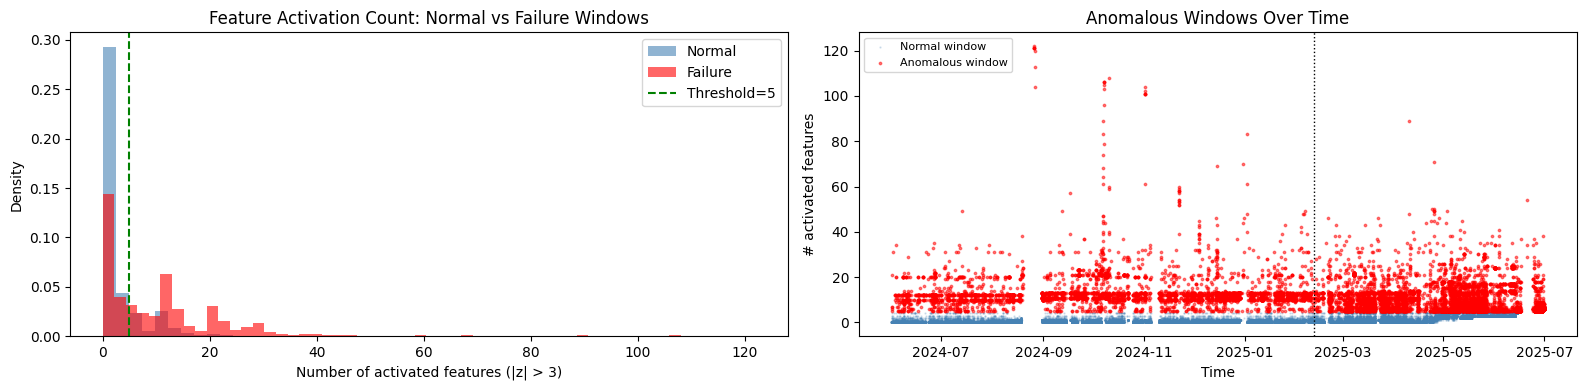

In [2]:
# Compute z-scores relative to train-normal distribution
train_normal = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
feat_means = train_normal[feature_cols].mean()
feat_stds = train_normal[feature_cols].std()
feat_stds = feat_stds.replace(0, 1)  # avoid division by zero
del train_normal; gc.collect()

# Z-score all windows
Z_THRESH = 3.0  # a feature is "activated" if |z| > 3
zscores = (all_sup[feature_cols] - feat_means) / feat_stds
activations = (zscores.abs() > Z_THRESH).astype(int)  # binary: 1 = anomalous feature

# Count activated features per window
all_sup['n_activated'] = activations.sum(axis=1)

# A window is "anomalous" if >= 5 features are activated
MIN_ACTIVATED = 5
all_sup['is_anomalous'] = (all_sup['n_activated'] >= MIN_ACTIVATED).astype(int)

n_anom = all_sup['is_anomalous'].sum()
n_anom_fail = all_sup.loc[all_sup['is_anomalous'] == 1, 'label'].sum()
n_anom_normal = n_anom - n_anom_fail

print(f'Z-score threshold: |z| > {Z_THRESH}')
print(f'Min activated features: {MIN_ACTIVATED}')
print(f'\nAnomalous windows: {n_anom} / {len(all_sup)} ({100*n_anom/len(all_sup):.1f}%)')
print(f'  With failure label: {n_anom_fail} ({100*n_anom_fail/max(n_anom,1):.1f}%)')
print(f'  Without failure label: {n_anom_normal} ({100*n_anom_normal/max(n_anom,1):.1f}%)')
print(f'\nFor comparison:')
print(f'  Total failure windows: {all_sup["label"].sum()}')
print(f'  Failure windows that are anomalous: {n_anom_fail} ({100*n_anom_fail/max(all_sup["label"].sum(),1):.1f}%)')

# Distribution of n_activated
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

ax = axes[0]
ax.hist(all_sup.loc[all_sup['label']==0, 'n_activated'], bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(all_sup.loc[all_sup['label']==1, 'n_activated'], bins=50, alpha=0.6, color='red', label='Failure', density=True)
ax.axvline(MIN_ACTIVATED, color='green', linestyle='--', label=f'Threshold={MIN_ACTIVATED}')
ax.set_xlabel('Number of activated features (|z| > 3)')
ax.set_ylabel('Density')
ax.set_title('Feature Activation Count: Normal vs Failure Windows')
ax.legend()

ax = axes[1]
ax.scatter(all_sup.loc[all_sup['is_anomalous']==0, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==0, 'n_activated'],
           s=0.5, alpha=0.2, c='steelblue', label='Normal window')
ax.scatter(all_sup.loc[all_sup['is_anomalous']==1, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==1, 'n_activated'],
           s=3, alpha=0.5, c='red', label='Anomalous window')
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('# activated features')
ax.set_title('Anomalous Windows Over Time')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

## 2. Feature Activation Profiles

For each anomalous window, we have a binary vector: which of the 340 features are activated (|z| > 3)?

This is the "fingerprint" of each anomaly â€” which sensors are behaving unusually.

In [3]:
# Extract activation profiles for anomalous windows only
anom_mask = all_sup['is_anomalous'] == 1
anom_orig_idx = all_sup.index[anom_mask]  # original indices into all_sup
anom_activations = activations.loc[anom_mask].reset_index(drop=True)
anom_meta = all_sup.loc[anom_mask, ['window_end', 'label', 'split', 'n_activated']].reset_index(drop=True)

print(f'Anomalous windows: {len(anom_activations)}')
print(f'Activation matrix shape: {anom_activations.shape}')

# Which features are most commonly activated?
feat_freq = anom_activations.sum().sort_values(ascending=False)
feat_freq_pct = (feat_freq / len(anom_activations) * 100).round(1)

print(f'\nTop 30 most frequently activated features:')
top30 = feat_freq.head(30)
for f, count in top30.items():
    pct = count / len(anom_activations) * 100
    print(f'  {f:55s} {count:5d} ({pct:5.1f}%)')

# Never-activated features
never_activated = (feat_freq == 0).sum()
print(f'\nFeatures never activated: {never_activated} / {len(feature_cols)}')

Anomalous windows: 12022
Activation matrix shape: (12022, 266)

Top 30 most frequently activated features:
  MW4_LOAD_SIGNAL_min                                      3925 ( 32.6%)
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                   3644 ( 30.3%)
  MW4_ENERGY_BRAKING_RESISTANCE_max                        3471 ( 28.9%)
  MW4_ENERGY_BRAKING_RESISTANCE_mean                       3468 ( 28.8%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3258 ( 27.1%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3053 ( 25.4%)
  MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   3019 ( 25.1%)
  MW4_ENERGY_BRAKING_RESISTANCE_min                        2885 ( 24.0%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2676 ( 22.3%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2661 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   2653 ( 22.1%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   2649 ( 22.0%)
  CW2_BRAKE_CYLIN

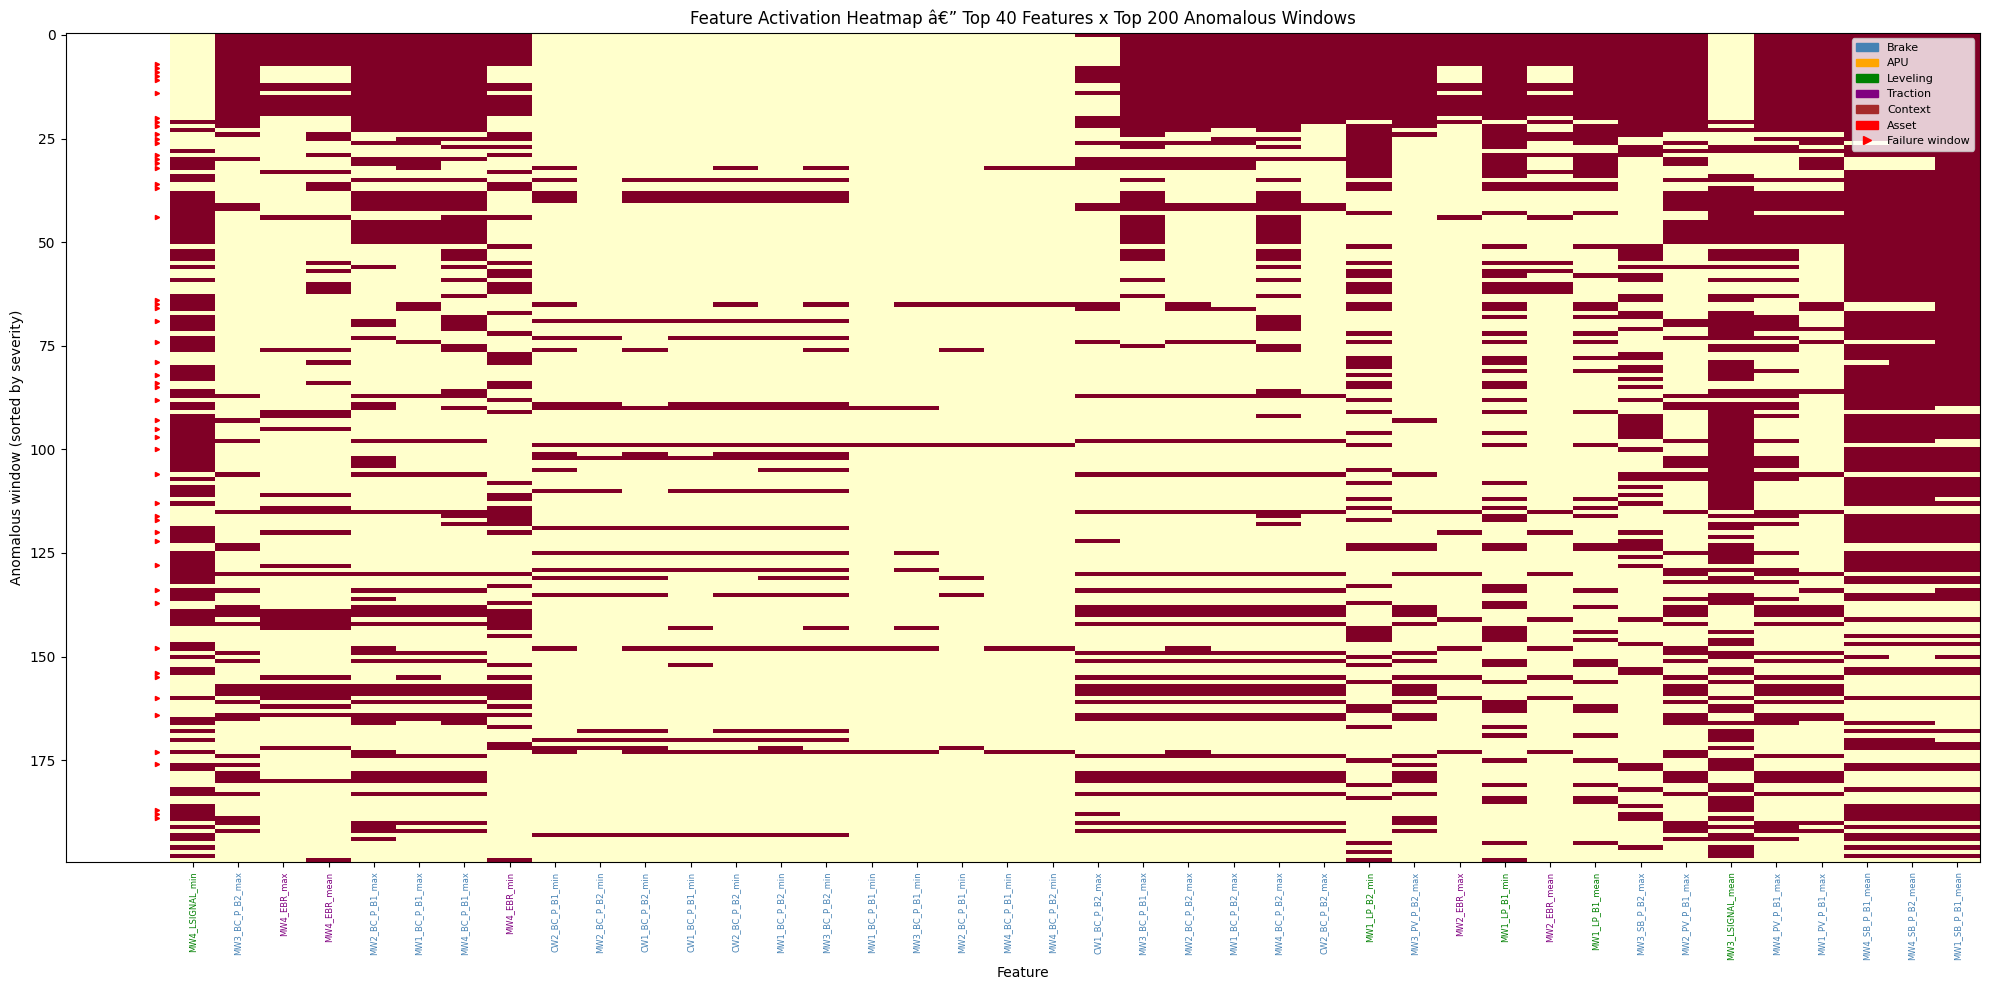

In [4]:
# Visualize: top 40 features activation heatmap (sample of anomalous windows)
top40_feats = feat_freq.head(40).index.tolist()
top40_subs = [feat_subsystem[f] for f in top40_feats]

# Sort anomalous windows by number of activations (most anomalous first)
sort_idx = anom_meta['n_activated'].argsort()[::-1]
sample_idx = sort_idx[:min(200, len(sort_idx))]  # top 200 most anomalous

heatmap_data = anom_activations.iloc[sample_idx][top40_feats].values

fig, ax = plt.subplots(figsize=(20, 10))
im = ax.imshow(heatmap_data, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax.set_xlabel('Feature')
ax.set_ylabel('Anomalous window (sorted by severity)')
ax.set_title(f'Feature Activation Heatmap â€” Top 40 Features x Top {len(sample_idx)} Anomalous Windows')

# Color-code x-axis by subsystem
sub_colors = {'Brake': 'steelblue', 'APU': 'orange', 'Leveling': 'green',
              'Traction': 'purple', 'Context': 'brown', 'Asset': 'red'}
ax.set_xticks(range(len(top40_feats)))
short_labels = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
                .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
                .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
                .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
                for f in top40_feats]
ax.set_xticklabels(short_labels, rotation=90, fontsize=6)
for i, sub in enumerate(top40_subs):
    ax.get_xticklabels()[i].set_color(sub_colors.get(sub, 'black'))

# Mark failure windows on y-axis
fail_rows = anom_meta.iloc[sample_idx]['label'].values
for i, is_fail in enumerate(fail_rows):
    if is_fail:
        ax.plot(-0.8, i, 'r>', markersize=3)

legend_patches = [Patch(color=c, label=s) for s, c in sub_colors.items()]
legend_patches.append(plt.Line2D([0], [0], marker='>', color='red', linestyle='', label='Failure window'))
ax.legend(handles=legend_patches, loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

## 3. Cluster Recurring Anomaly Patterns

Use hierarchical clustering on the binary activation profiles to find groups of anomalous windows that share similar sensor activation patterns.

**Distance metric:** Jaccard distance (appropriate for binary data â€” measures overlap of activated features).
**Linkage:** Ward's method.

Features activated in >= 120 windows: 130 / 266
Computing Jaccard distances...


Computing hierarchical clustering (Ward linkage)...


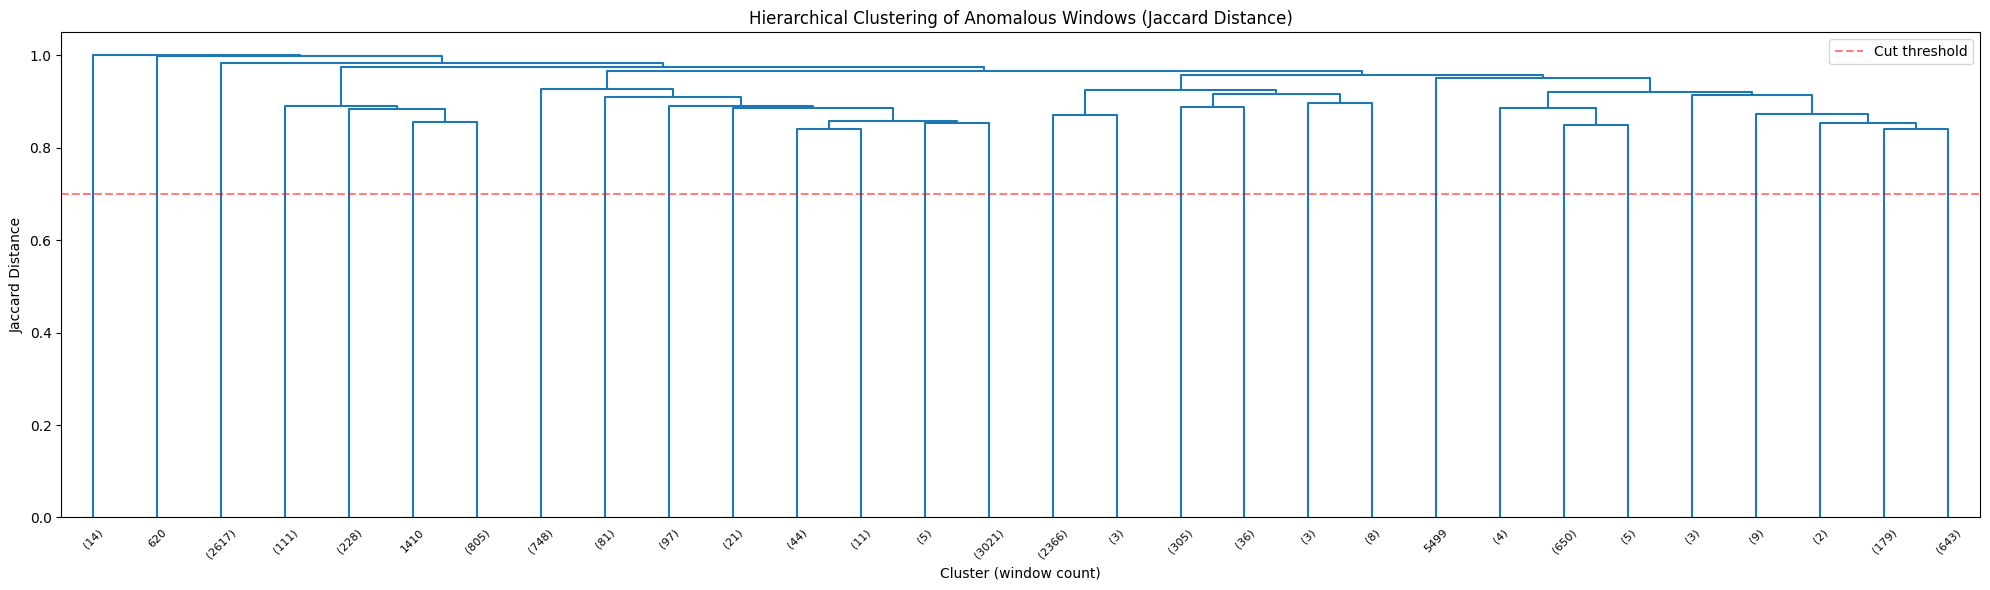

In [5]:
# Filter to features that are activated in at least 1% of anomalous windows
min_freq = max(int(len(anom_activations) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f'Features activated in >= {min_freq} windows: {len(active_feats)} / {len(feature_cols)}')

# Compute Jaccard distance between anomalous windows
anom_binary = anom_activations[active_feats].values

print('Computing Jaccard distances...')
dist_matrix = pdist(anom_binary, metric='jaccard')

print('Computing hierarchical clustering (Ward linkage)...')
Z = linkage(dist_matrix, method='average')  # average linkage works better with Jaccard

# Plot dendrogram
fig, ax = plt.subplots(figsize=(20, 6))
dn = dendrogram(Z, ax=ax, truncate_mode='lastp', p=30, show_leaf_counts=True,
                leaf_font_size=8, color_threshold=0.7)
ax.set_xlabel('Cluster (window count)')
ax.set_ylabel('Jaccard Distance')
ax.set_title('Hierarchical Clustering of Anomalous Windows (Jaccard Distance)')
ax.axhline(0.7, color='red', linestyle='--', alpha=0.5, label='Cut threshold')
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# Try multiple cut thresholds and pick one that gives interpretable clusters
for t in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9]:
    labels = fcluster(Z, t=t, criterion='distance')
    n_clusters = len(set(labels))
    sizes = pd.Series(labels).value_counts().sort_index()
    print(f't={t:.2f}: {n_clusters} clusters | sizes: {sizes.values[:10]}...')

# Select a cut threshold (adjust based on dendrogram)
CUT_THRESHOLD = 0.75
cluster_labels = fcluster(Z, t=CUT_THRESHOLD, criterion='distance')
anom_meta['cluster'] = cluster_labels

# Filter out tiny clusters (< 5 windows) â€” likely noise
cluster_sizes = anom_meta['cluster'].value_counts()
valid_clusters = cluster_sizes[cluster_sizes >= 5].index.tolist()
anom_meta['cluster_clean'] = anom_meta['cluster'].where(anom_meta['cluster'].isin(valid_clusters), other=-1)

n_valid = len(valid_clusters)
n_noise = (anom_meta['cluster_clean'] == -1).sum()
print(f'\nCut threshold: {CUT_THRESHOLD}')
print(f'Valid clusters (>= 5 windows): {n_valid}')
print(f'Noise windows (tiny clusters): {n_noise}')

t=0.50: 576 clusters | sizes: [14  1  1  2  1  5 14 15  1 93]...
t=0.60: 281 clusters | sizes: [  14    1    1    2    1    5   30 2573    2    1]...
t=0.70: 117 clusters | sizes: [  14    2 2614    1   52   15    6   38   30   97]...
t=0.80: 38 clusters | sizes: [  14 2617   67   44  228  805    1  748   81   20]...


t=0.85: 27 clusters | sizes: [  14 2617  111  228  805    1  748   81   97   21]...
t=0.90: 14 clusters | sizes: [  14 2617 1145  748   81 3199 2369  341   11  659]...

Cut threshold: 0.75
Valid clusters (>= 5 windows): 49
Noise windows (tiny clusters): 44


In [7]:
# ── Cluster summary ──
print(f'\n{"="*80}')
print(f'{"Cluster":>8} {"Size":>6} {"Failure":>8} {"Fail%":>7} {"Train":>6} {"Test":>6} {"Mean Act":>9}')
print(f'{"="*80}')

cluster_profiles = {}
for cl in sorted(valid_clusters):
    cl_mask = anom_meta['cluster_clean'] == cl
    cl_meta = anom_meta[cl_mask]
    cl_acts = anom_activations.loc[cl_mask.values, active_feats]
    
    size = len(cl_meta)
    n_fail = cl_meta['label'].sum()
    n_train = (cl_meta['split'] == 'train').sum()
    n_test = (cl_meta['split'] == 'test').sum()
    mean_act = cl_meta['n_activated'].mean()
    
    cluster_profiles[cl] = {
        'size': size, 'n_fail': n_fail, 'fail_pct': n_fail / size * 100,
        'n_train': n_train, 'n_test': n_test, 'mean_activated': mean_act,
    }
    
    print(f'{cl:>8} {size:>6} {n_fail:>8} {n_fail/size*100:>6.1f}% {n_train:>6} {n_test:>6} {mean_act:>9.1f}')

print(f'{"="*80}')
print(f'{"TOTAL":>8} {sum(c["size"] for c in cluster_profiles.values()):>6} '
      f'{sum(c["n_fail"] for c in cluster_profiles.values()):>8}')


 Cluster   Size  Failure   Fail%  Train   Test  Mean Act
       1     14        0    0.0%     13      1       7.6
       2   2617       85    3.2%   1780    837      13.3
       3     52       12   23.1%     11     41      31.3
       4     15        2   13.3%     10      5      11.8
       5      6        6  100.0%      6      0      28.3
       6     38       19   50.0%     36      2      90.5
       7     30        2    6.7%     10     20       7.8


       8    198       15    7.6%    125     73      22.3
      10    802      146   18.2%    451    351      20.6
      13    748      135   18.0%    748      0      13.0
      14     81       35   43.2%     81      0      13.6
      15      6        0    0.0%      0      6       7.0
      16     14        0    0.0%      0     14       6.7
      17     13        0    0.0%      0     13       7.7
      18     17        0    0.0%      0     17       9.5
      19     47        1    2.1%      0     47       7.1
      20     13        0    0.0%      0     13       7.4


      22      6        1   16.7%      0      6       5.7
      23      9        0    0.0%      0      9       6.9
      24     34        0    0.0%      0     34       6.1
      26      5        5  100.0%      0      5      11.2
      29      5        5  100.0%      0      5      30.0
      31   2059       72    3.5%   1385    674      10.9
      33     17        0    0.0%      0     17       6.2
      34     38        0    0.0%      0     38       7.9


      35     35        2    5.7%      0     35       9.6
      36    815       20    2.5%     35    780      11.9
      37     37        1    2.7%      0     37       6.8
      38     17        1    5.9%      0     17       6.5
      39   2366       54    2.3%      0   2366       6.2
      42    301       13    4.3%     61    240       6.8
      43     23       20   87.0%     22      1       8.7
      44      5        0    0.0%      3      2       6.4
      45      8        1   12.5%      2      6       6.9


      47      8        2   25.0%      2      6       8.9
      50     15        0    0.0%     15      0       6.7
      51    635       58    9.1%      3    632       6.2
      55      7        0    0.0%      7      0       6.7
      58      5        0    0.0%      5      0      13.6
      59    152        2    1.3%     62     90       6.3
      60     22        0    0.0%     20      2       6.2
      61      5        0    0.0%      5      0       5.0
      62    199        0    0.0%    194      5      10.8


      63     99        0    0.0%     79     20       7.2
      64    249        4    1.6%    167     82      17.5
      65     30        0    0.0%      1     29       7.7
      66     19        0    0.0%      0     19      18.3
      67      7        0    0.0%      0      7       5.4
      68     35        0    0.0%      2     33       7.9
   TOTAL  11978      719


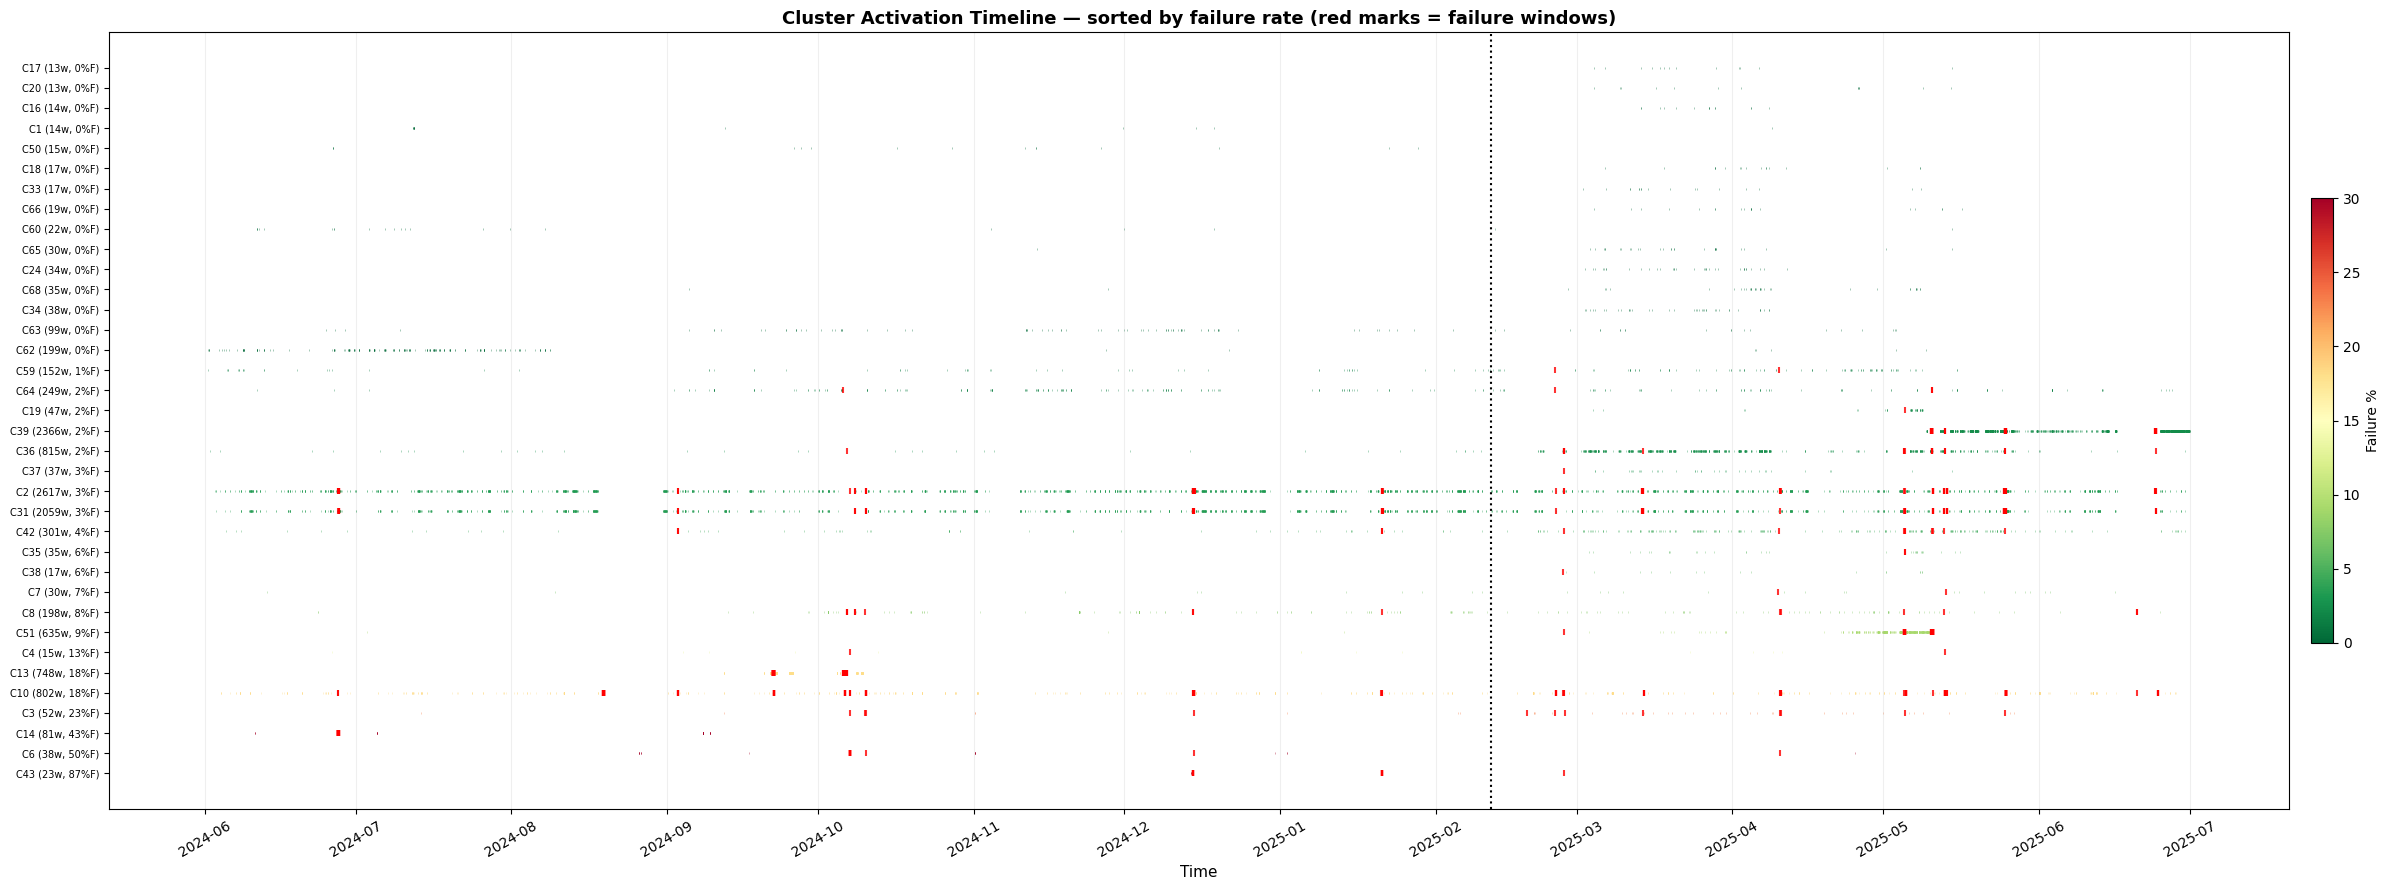


Cluster temporal coverage:
  Train-only: 3 clusters — ['C14', 'C13', 'C50']
  Test-only:  13 clusters — ['C38', 'C35', 'C37', 'C39', 'C19', 'C34', 'C24', 'C66', 'C33', 'C18', 'C16', 'C20', 'C17']
  Both:       20 clusters


In [8]:
# ── Cluster activation timeline ──
# Show when each cluster is active, colored by failure rate

# Sort clusters: high failure rate on top
cl_order = sorted(valid_clusters, 
                  key=lambda c: cluster_profiles[c]['fail_pct'], reverse=True)

# Only show clusters with >= 10 windows for readability
cl_show = [c for c in cl_order if cluster_profiles[c]['size'] >= 10]

fig, ax = plt.subplots(figsize=(24, max(6, len(cl_show) * 0.25)))

# Color by failure rate
cmap = plt.cm.RdYlGn_r
norm = plt.Normalize(0, 30)  # cap at 30% for color range

for row, cl in enumerate(cl_show):
    cl_mask = anom_meta['cluster_clean'] == cl
    cl_idx = anom_orig_idx[cl_mask.values]
    times = all_sup.loc[cl_idx, 'window_end']
    labels = anom_meta.loc[cl_mask, 'label'].values
    
    fail_pct = cluster_profiles[cl]['fail_pct']
    color = cmap(norm(fail_pct))
    
    # Normal windows
    norm_times = times[labels == 0]
    ax.scatter(norm_times, [row] * len(norm_times), 
               s=2, c=[color], alpha=0.5, marker='|', linewidths=0.5)
    
    # Failure windows
    fail_times = times[labels == 1]
    if len(fail_times) > 0:
        ax.scatter(fail_times, [row] * len(fail_times),
                   s=15, c='red', alpha=0.8, marker='|', linewidths=1.5, zorder=5)

# Train/test split
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1.5, label='Train/Test split')

# Y-axis labels with cluster info
ylabels = []
for cl in cl_show:
    p = cluster_profiles[cl]
    ylabels.append(f"C{cl} ({p['size']}w, {p['fail_pct']:.0f}%F)")

ax.set_yticks(range(len(cl_show)))
ax.set_yticklabels(ylabels, fontsize=7)
ax.set_xlabel('Time', fontsize=11)
ax.set_title('Cluster Activation Timeline — sorted by failure rate (red marks = failure windows)', 
             fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, fraction=0.01, pad=0.01)
cbar.set_label('Failure %')

ax.grid(True, alpha=0.2, axis='x')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'cluster_activation_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()

# Print which clusters are train-only vs test-only vs both
print('\nCluster temporal coverage:')
train_only = [c for c in cl_show if cluster_profiles[c]['n_test'] == 0]
test_only = [c for c in cl_show if cluster_profiles[c]['n_train'] == 0]
both = [c for c in cl_show if cluster_profiles[c]['n_train'] > 0 and cluster_profiles[c]['n_test'] > 0]
print(f'  Train-only: {len(train_only)} clusters — {[f"C{c}" for c in train_only]}')
print(f'  Test-only:  {len(test_only)} clusters — {[f"C{c}" for c in test_only]}')
print(f'  Both:       {len(both)} clusters')

## 4. Full Cluster Statistical Analysis

For each of the 51 clusters we compute five key metrics:

| Metric | What it measures | Why it matters |
|--------|-----------------|----------------|
| **Features / Sensors** | How many windowed features (and underlying physical sensors) belong to this cluster | Larger clusters capture broader system behavior; single-feature clusters may be sensor-specific |
| **Active Windows** | Number of anomalous windows where ≥1 feature in this cluster fires | Shows how frequently this pattern appears in the data |
| **Failure %** | Fraction of active windows that overlap with a labeled failure period | High failure % → the pattern is predictive; low → could be normal operational variation |
| **Coherence (avg corr)** | Mean pairwise absolute correlation among the cluster's features | High coherence (≥0.7) means the features genuinely move together — the cluster is physically meaningful |
| **Signal Shift (σ)** | How far the cluster's features deviate from their normal-condition mean (in standard deviations) | Large shift → the anomaly is strong and detectable; small shift → subtle or noisy |

In [9]:
# ── Full cluster statistical analysis ──
sample_idx = np.random.RandomState(42).choice(len(all_sup), size=min(5000, len(all_sup)), replace=False)

header = f"{'CL':>4} | {'Feats':>5} | {'Sensors':>7} | {'Windows':>7} | {'Fail':>5} | {'Fail%':>6} | {'Corr':>6} | {'Shift':>7} | Top Sensor"
print(header)
print('-' * len(header) + '-' * 40)

cluster_stats = []
for cl_id in sorted(valid_clusters):
    cl_mask = anom_meta['cluster_clean'] == cl_id
    feats = [f for f in active_feats if anom_activations.loc[cl_mask.values, f].sum() > 0]
    if not feats:
        feats = active_feats[:1]

    sensors = set()
    for f in feats:
        for suf in ['_min','_max','_mean','_sum','_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break

    n_win = int(cl_mask.sum())
    n_fail = int(anom_meta.loc[cl_mask, 'label'].sum()) if n_win > 0 else 0
    fail_pct = 100 * n_fail / max(n_win, 1)

    if len(feats) >= 3:
        corr = all_sup.iloc[sample_idx][feats].corr().abs()
        avg_corr = corr.values[np.triu_indices(len(feats), k=1)].mean()
    elif len(feats) == 2:
        avg_corr = all_sup.iloc[sample_idx][feats].corr().abs().iloc[0,1]
    else:
        avg_corr = 1.0

    shifts = []
    for f in feats:
        nm = all_sup.loc[all_sup['label']==0, f].mean()
        ns = all_sup.loc[all_sup['label']==0, f].std()
        if ns > 0 and n_win > 0:
            am = all_sup.loc[anom_orig_idx[cl_mask.values], f].mean()
            shifts.append(abs(am - nm) / ns)
    avg_shift = np.mean(shifts) if shifts else 0

    top_feat = feats[0]
    top_sensor = top_feat
    for suf in ['_min','_max','_mean','_sum','_flips']:
        if top_sensor.endswith(suf):
            top_sensor = top_sensor[:-len(suf)]
            break

    print(f"C{cl_id:>3} | {len(feats):>5} | {len(sensors):>7} | {n_win:>7} | {n_fail:>5} | {fail_pct:>5.1f}% | {float(avg_corr):>5.2f} | {float(avg_shift):>6.1f}\u03c3 | {top_sensor}")

    cluster_stats.append({
        'cluster': int(cl_id), 'n_features': len(feats), 'n_sensors': len(sensors),
        'n_windows': int(n_win), 'n_failures': int(n_fail),
        'fail_pct': round(float(fail_pct), 1), 'avg_corr': round(float(avg_corr), 3),
        'avg_shift_sigma': round(float(avg_shift), 2), 'top_sensor': top_sensor,
        'sensors': sorted(sensors), 'features': feats,
    })

# Save
import json as _json
with open(os.path.join(OUT_DIR, 'cluster_statistics.json'), 'w') as _f:
    _json.dump(cluster_stats, _f, indent=2)

# Summary
print(f"\n{'='*80}")
print("SUMMARY")
print(f"{'='*80}")
high_fail = [r for r in cluster_stats if r['fail_pct'] >= 10]
high_corr = [r for r in cluster_stats if r['avg_corr'] >= 0.7]
big = [r for r in cluster_stats if r['n_windows'] >= 500]
print(f"Total clusters: {len(cluster_stats)}")
print(f"Clusters with fail% >= 10%: {len(high_fail)}")
print(f"Clusters with coherence >= 0.7: {len(high_corr)}")
print(f"Large clusters (>= 500 windows): {len(big)}")

print("\n--- Top 10 by failure rate ---")
for r in sorted(cluster_stats, key=lambda x: x['fail_pct'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['fail_pct']}% failure, {r['n_windows']} windows, corr={r['avg_corr']}")

print("\n--- Top 10 by window count ---")
for r in sorted(cluster_stats, key=lambda x: x['n_windows'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['n_windows']} windows, {r['fail_pct']}% failure, corr={r['avg_corr']}")

print("\n--- Top 10 by signal shift ---")
for r in sorted(cluster_stats, key=lambda x: x['avg_shift_sigma'], reverse=True)[:10]:
    print(f"  C{r['cluster']}: {r['avg_shift_sigma']}\u03c3 shift, {r['fail_pct']}% failure, corr={r['avg_corr']}")

  CL | Feats | Sensors | Windows |  Fail |  Fail% |   Corr |   Shift | Top Sensor
-------------------------------------------------------------------------------------------------------------------------
C  1 |     1 |       1 |      14 |     0 |   0.0% |  1.00 |    0.4σ | MW4_LOAD_SIGNAL


C  2 |    84 |      47 |    2617 |    85 |   3.2% |  0.24 |    1.2σ | MW4_LOAD_SIGNAL


C  3 |    84 |      42 |      52 |    12 |  23.1% |  0.29 |    2.8σ | MW4_ENERGY_BRAKING_RESISTANCE
C  4 |    18 |      17 |      15 |     2 |  13.3% |  0.47 |    2.9σ | MW4_LOAD_SIGNAL
C  5 |    34 |      24 |       6 |     6 | 100.0% |  0.30 |    4.8σ | MW4_LOAD_SIGNAL


C  6 |   122 |      66 |      38 |    19 |  50.0% |  0.27 |    4.6σ | MW4_LOAD_SIGNAL
C  7 |    26 |      17 |      30 |     2 |   6.7% |  0.20 |    1.7σ | MW4_LOAD_SIGNAL


C  8 |   111 |      61 |     198 |    15 |   7.6% |  0.27 |    1.9σ | MW4_LOAD_SIGNAL


...

C 51 |    77 |      54 |     635 |    58 |   9.1% |  0.25 |    0.4σ | MW4_LOAD_SIGNAL
C 55 |    14 |      10 |       7 |     0 |   0.0% |  0.42 |    2.7σ | MW1_LOAD_PRESSURE_BOGIE1
C 58 |    17 |      13 |       5 |     0 |   0.0% |  0.49 |    6.3σ | CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2


C 59 |    41 |      25 |     152 |     2 |   1.3% |  0.30 |    1.4σ | MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2
C 60 |    24 |      13 |      22 |     0 |   0.0% |  0.38 |    2.2σ | MW4_ENERGY_BRAKING_RESISTANCE
C 61 |    10 |       5 |       5 |     0 |   0.0% |  0.43 |    2.8σ | MW1_LOAD_PRESSURE_BOGIE2


C 62 |    35 |      17 |     199 |     0 |   0.0% |  0.35 |    2.4σ | MW4_ENERGY_BRAKING_RESISTANCE
C 63 |    36 |      18 |      99 |     0 |   0.0% |  0.33 |    1.9σ | MW4_LOAD_SIGNAL


C 64 |    56 |      32 |     249 |     4 |   1.6% |  0.26 |    1.9σ | MW4_LOAD_SIGNAL
C 65 |    38 |      26 |      30 |     0 |   0.0% |  0.30 |    1.8σ | MW4_ENERGY_BRAKING_RESISTANCE


C 66 |    46 |      34 |      19 |     0 |   0.0% |  0.32 |    2.5σ | MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2
C 67 |    14 |      11 |       7 |     0 |   0.0% |  0.25 |    1.8σ | MW4_LOAD_SIGNAL
C 68 |    38 |      27 |      35 |     0 |   0.0% |  0.30 |    1.8σ | MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2

SUMMARY
Total clusters: 49
Clusters with fail% >= 10%: 13
Clusters with coherence >= 0.7: 1
Large clusters (>= 500 windows): 7

--- Top 10 by failure rate ---
  C5: 100.0% failure, 6 windows, corr=0.301
  C26: 100.0% failure, 5 windows, corr=0.42
  C29: 100.0% failure, 5 windows, corr=0.287
  C43: 87.0% failure, 23 windows, corr=0.279
  C6: 50.0% failure, 38 windows, corr=0.275
  C14: 43.2% failure, 81 windows, corr=0.258
  C47: 25.0% failure, 8 windows, corr=0.176
  C3: 23.1% failure, 52 windows, corr=0.291
  C10: 18.2% failure, 802 windows, corr=0.274
  C13: 18.0% failure, 748 windows, corr=0.249

--- Top 10 by window count ---
  C2: 2617 windows, 3.2% failure, corr=0.241
  C39: 2366 windows,

## 5. Deep Dive: 5 Most Crucial Clusters

We select 5 clusters that cover different failure rates and sizes:

| Cluster | Fail% | Windows | Shift | Selection Reason |
|---------|-------|---------|-------|-----------------|
| **C43** | 87.0% | 23 | 4.2σ | Highest purity with sufficient data |
| **C6** | 50.0% | 38 | 4.6σ | Severe multi-sensor anomaly, large shift |
| **C10** | 18.2% | 802 | 1.4σ | Largest failure-relevant cluster |
| **C47** | 25.0% | 8 | 1.5σ | Distinct small cluster with high failure rate |
| **C51** | 9.1% | 635 | 0.4σ | Large cluster with moderate failure rate |

For each cluster we show:
1. **Top features** with min/max/mean/std in normal vs anomalous windows
2. **Temporal distribution** — when does this pattern appear?
3. **Variance trend** — is dispersion increasing before failures?
4. **Distribution shift** — normal vs anomalous feature distributions


CLUSTER C43: 23 windows, 20 failures (87.0%), 15 features

Feature                                             Normal Mean   Normal Std    Anom Mean     Anom Std  Shift (σ)
--------------------------------------------------------------------------------------------------------------
CW1_LOAD_SIGNAL_max                                      0.1481       0.1590       1.0000       0.0000       5.4σ
CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min                     0.6032       0.1388       0.0000       0.0000       4.3σ
CW1_LOAD_PRESSURE_BOGIE2_min                             0.1873       0.0206       0.0081       0.0391       8.7σ
CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips                     0.3691       0.9773      27.9130      20.3647      28.2σ
MW4_LOAD_SIGNAL_min                                      0.1276       0.2881       0.6974       0.4181       2.0σ


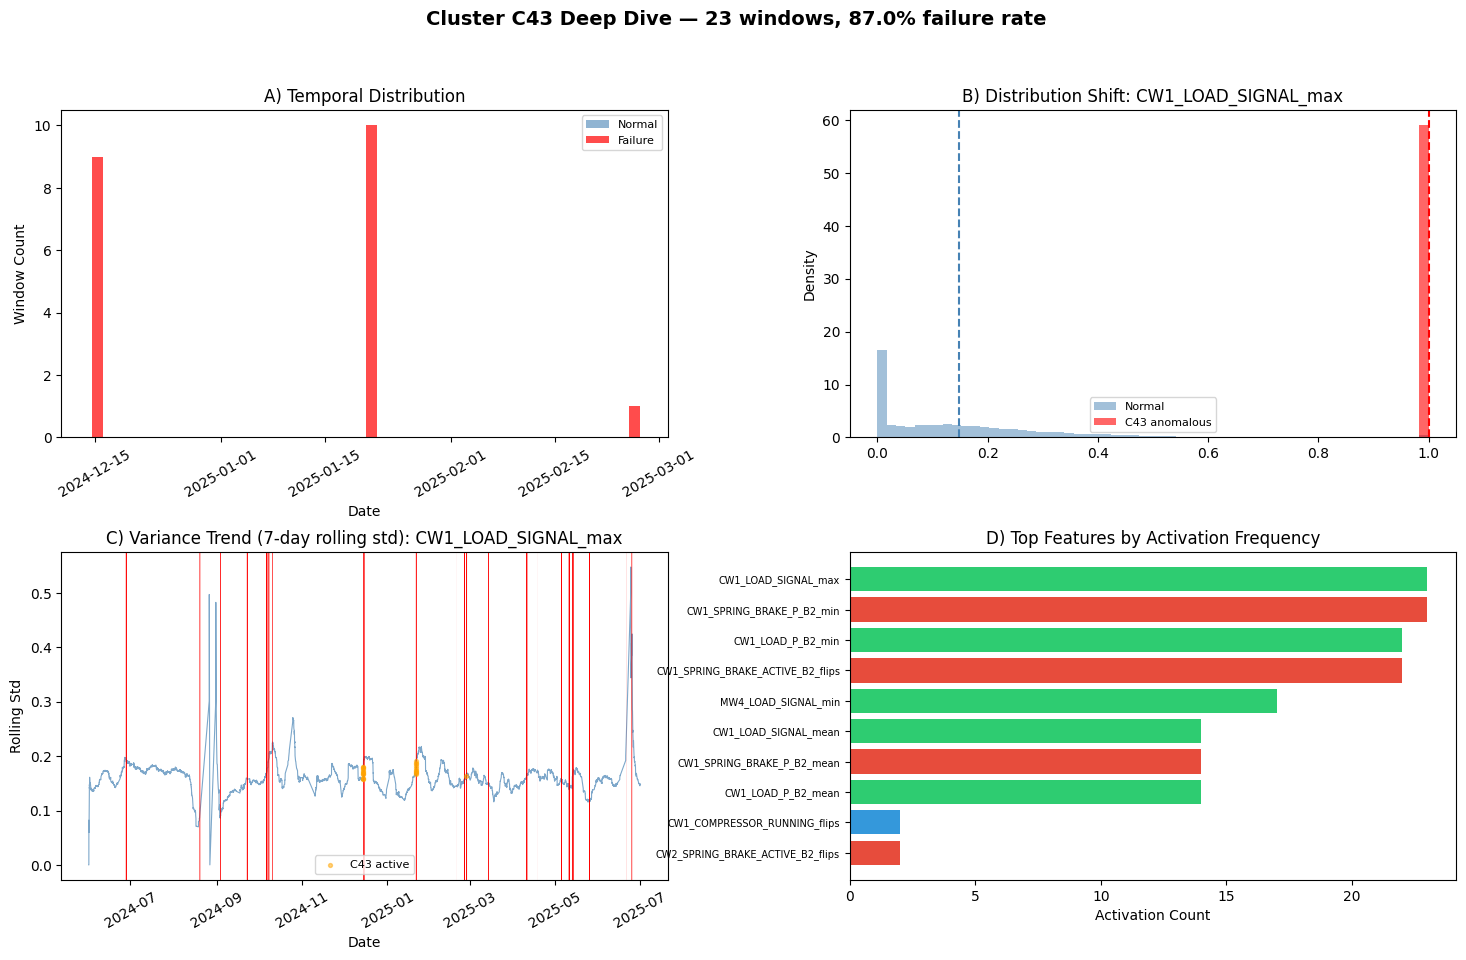


CLUSTER C6: 38 windows, 19 failures (50.0%), 122 features

Feature                                             Normal Mean   Normal Std    Anom Mean     Anom Std  Shift (σ)
--------------------------------------------------------------------------------------------------------------
MW2_SPRING_BRAKE_PRESSURE_BOGIE2_mean                    0.6685       0.0911       0.0284       0.0682       7.0σ
MW1_SPRING_BRAKE_PRESSURE_BOGIE1_mean                    0.6624       0.0903       0.0254       0.0619       7.1σ
MW2_SPRING_BRAKE_PRESSURE_BOGIE2_min                     0.6017       0.1353       0.0034       0.0201       4.4σ
MW1_SPRING_BRAKE_PRESSURE_BOGIE1_min                     0.5966       0.1351       0.0010       0.0056       4.4σ
MW2_LOAD_PRESSURE_BOGIE2_min                             0.2270       0.0256       0.0063       0.0250       8.6σ


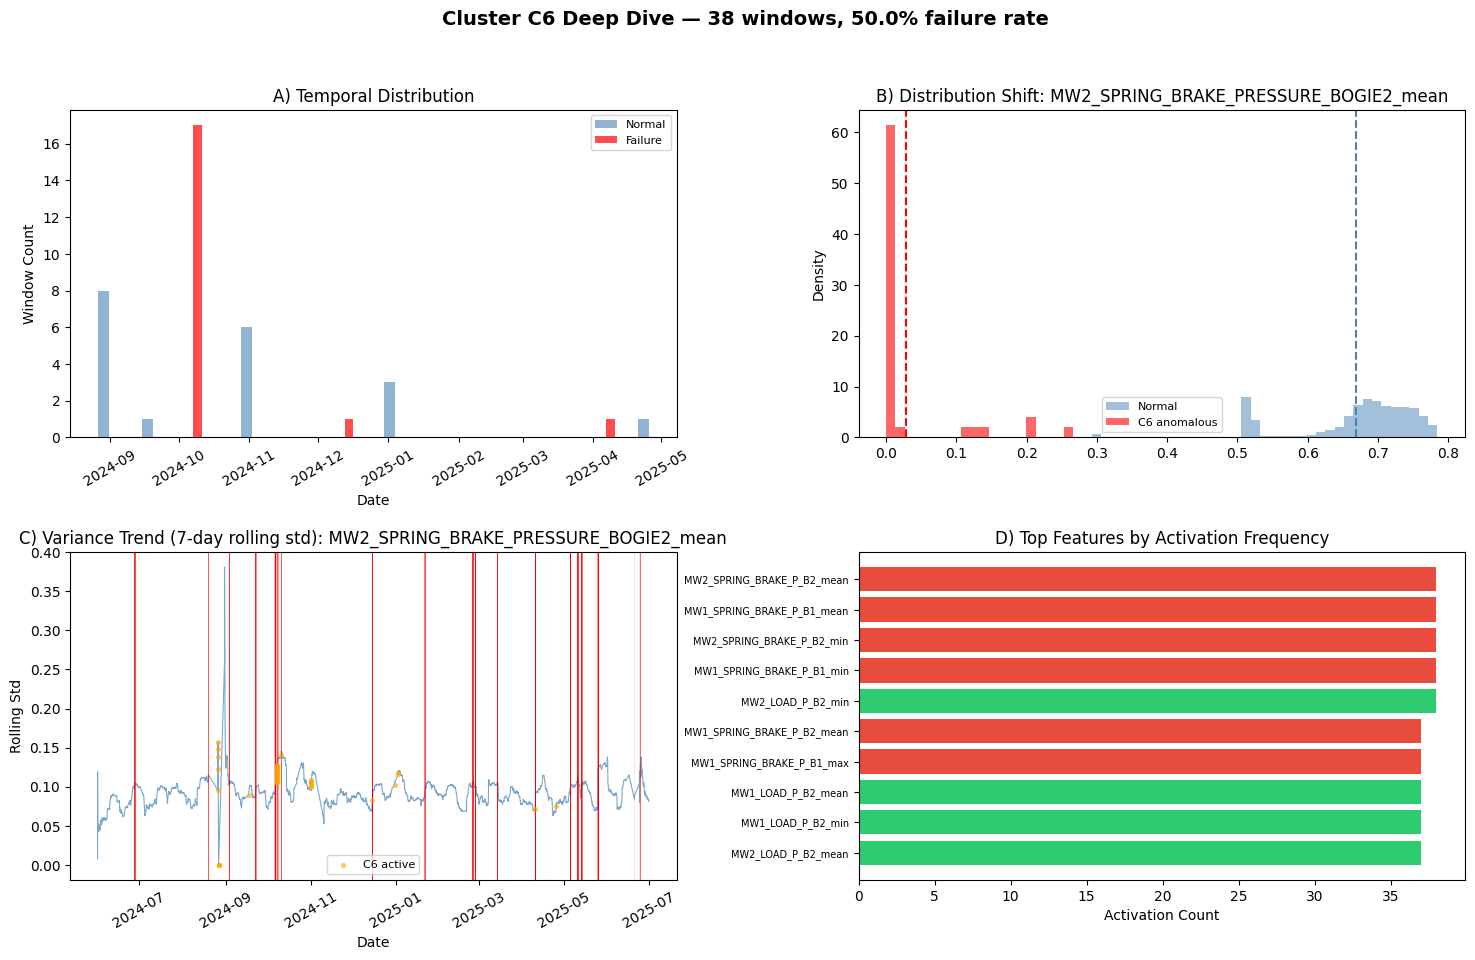


CLUSTER C10: 802 windows, 146 failures (18.2%), 110 features

Feature                                             Normal Mean   Normal Std    Anom Mean     Anom Std  Shift (σ)
--------------------------------------------------------------------------------------------------------------
MW2_SPRING_BRAKE_PRESSURE_BOGIE2_mean                    0.6685       0.0911       0.3014       0.0534       4.0σ
MW3_SPRING_BRAKE_PRESSURE_BOGIE1_mean                    0.6661       0.0911       0.3065       0.0307       3.9σ
CW2_SPRING_BRAKE_PRESSURE_BOGIE2_mean                    0.6702       0.0896       0.3092       0.0246       4.0σ
MW4_SPRING_BRAKE_PRESSURE_BOGIE2_mean                    0.6628       0.0916       0.2994       0.0416       4.0σ
CW1_SPRING_BRAKE_PRESSURE_BOGIE2_mean                    0.6703       0.0897       0.3029       0.0474       4.1σ


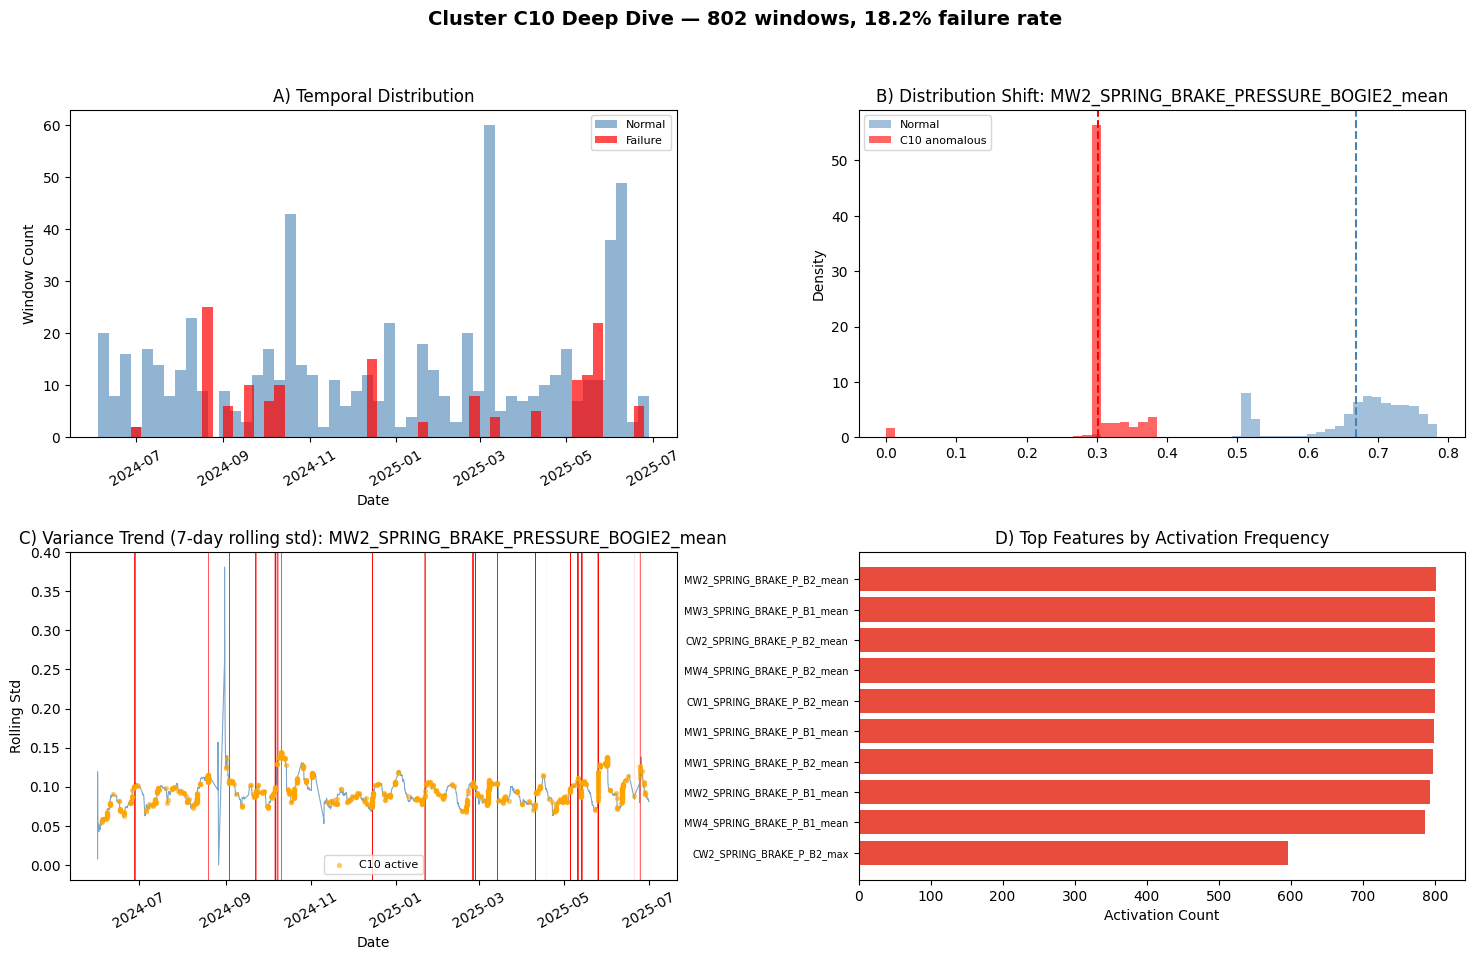


CLUSTER C47: 8 windows, 2 failures (25.0%), 7 features

Feature                                             Normal Mean   Normal Std    Anom Mean     Anom Std  Shift (σ)
--------------------------------------------------------------------------------------------------------------
CW2_COMPRESSOR_RUNNING_flips                             0.3122       0.7253       4.7500       1.8323       6.1σ
CW1_COMPRESSOR_RUNNING_flips                             0.4392       0.8949       2.5000       3.3806       2.3σ
MW4_LOAD_SIGNAL_min                                      0.1276       0.2881       0.1370       0.3255       0.0σ
CW1_LOAD_SIGNAL_max                                      0.1481       0.1590       0.1748       0.3395       0.2σ
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   0.0367       0.1181       0.0808       0.2176       0.4σ


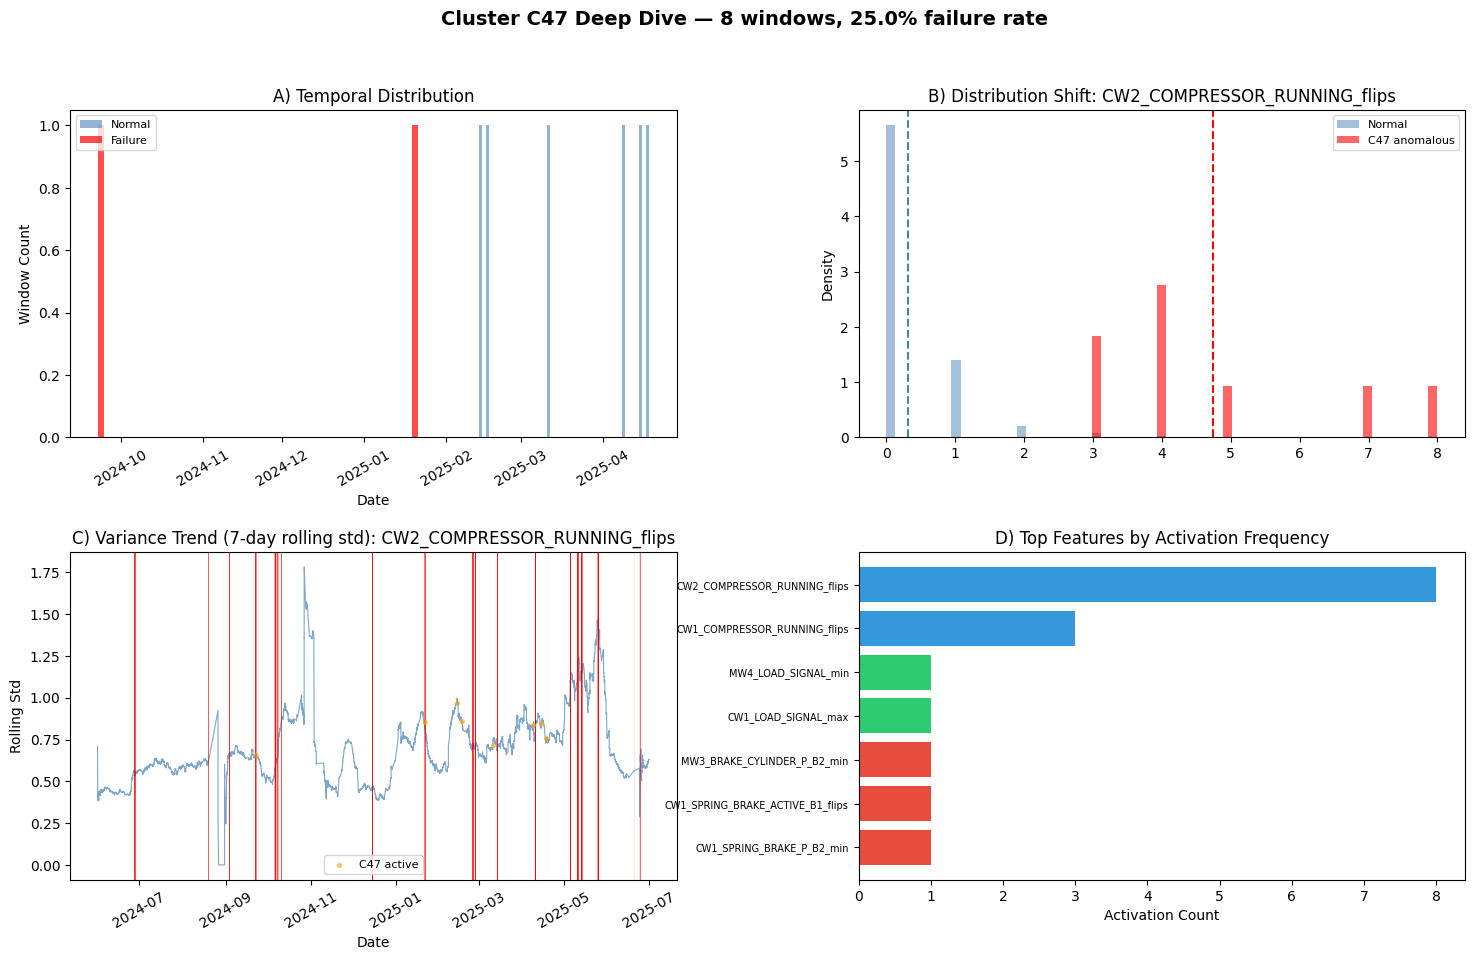


CLUSTER C51: 635 windows, 58 failures (9.1%), 77 features

Feature                                             Normal Mean   Normal Std    Anom Mean     Anom Std  Shift (σ)
--------------------------------------------------------------------------------------------------------------
MW1_LOAD_PRESSURE_BOGIE1_mean                            0.2295       0.0345       0.1369       0.0318       2.7σ
MW1_LOAD_PRESSURE_BOGIE1_min                             0.1957       0.0289       0.1264       0.0289       2.4σ
MW1_LOAD_PRESSURE_BOGIE1_max                             0.2827       0.0537       0.1461       0.0375       2.5σ
MW1_LOAD_PRESSURE_BOGIE2_min                             0.2011       0.0280       0.2685       0.0144       2.4σ
MW4_LOAD_SIGNAL_min                                      0.1276       0.2881       0.4407       0.4512       1.1σ


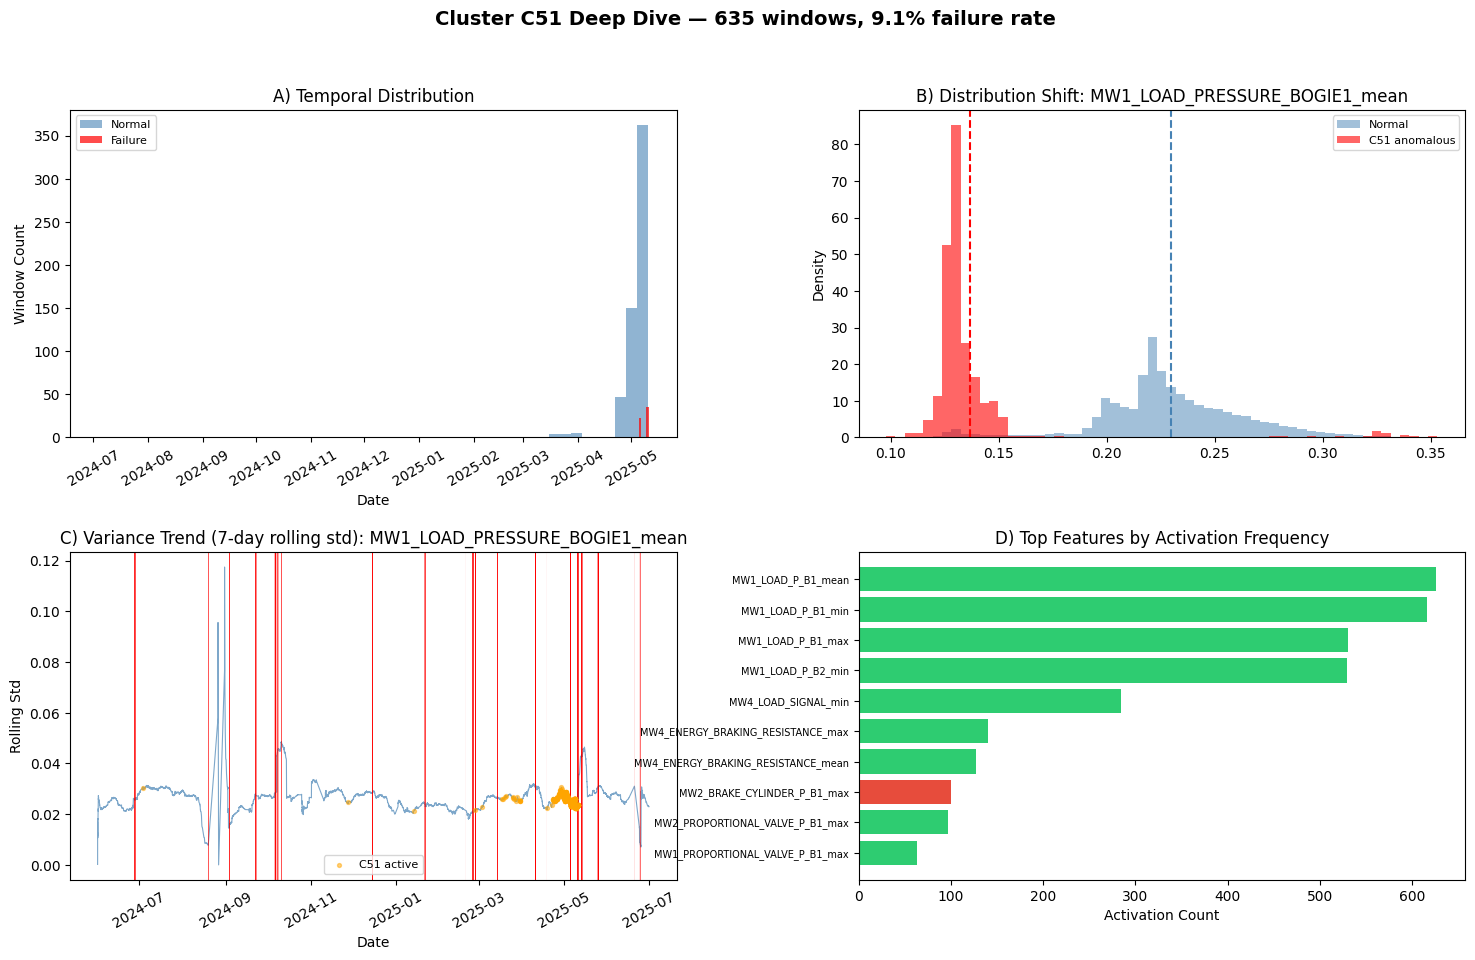


Deep dive complete for clusters: [43, 6, 10, 47, 51]


In [10]:
# ── Deep dive into 5 most crucial clusters ──
from matplotlib.gridspec import GridSpec

DIVE_CLUSTERS = [43, 6, 10, 47, 51]

# Ensure window_end is datetime
if 'window_end' not in all_sup.columns:
    all_sup['window_end'] = pd.to_datetime(all_sup['window_end'])

for cl_id in DIVE_CLUSTERS:
    cl_mask = anom_meta['cluster_clean'] == cl_id
    cl_idx = anom_orig_idx[cl_mask.values]  # map back to all_sup indices
    n_win = int(cl_mask.sum())
    n_fail = int(anom_meta.loc[cl_mask, 'label'].sum())
    fail_pct = 100 * n_fail / max(n_win, 1)
    
    # Get cluster features
    feats = [f for f in active_feats if anom_activations.loc[cl_mask.values, f].sum() > 0]
    if not feats:
        continue
    
    # Top 5 features by activation frequency
    feat_acts = anom_activations.loc[cl_mask.values, feats].sum().sort_values(ascending=False)
    top_feats = feat_acts.head(5).index.tolist()
    
    print(f"\n{'='*90}")
    print(f"CLUSTER C{cl_id}: {n_win} windows, {n_fail} failures ({fail_pct:.1f}%), {len(feats)} features")
    print(f"{'='*90}")
    
    # ── 1. Feature statistics: normal vs anomalous ──
    normal_mask = all_sup['label'] == 0
    print(f"\n{'Feature':<50} {'Normal Mean':>12} {'Normal Std':>12} {'Anom Mean':>12} {'Anom Std':>12} {'Shift (σ)':>10}")
    print('-' * 110)
    for f in top_feats:
        nm, ns = all_sup.loc[normal_mask, f].mean(), all_sup.loc[normal_mask, f].std()
        am, astd = all_sup.loc[cl_idx, f].mean(), all_sup.loc[cl_idx, f].std()
        shift = abs(am - nm) / ns if ns > 0 else 0
        print(f"{f:<50} {nm:>12.4f} {ns:>12.4f} {am:>12.4f} {astd:>12.4f} {shift:>9.1f}σ")
    
    # ── 2. Four-panel visualization ──
    fig = plt.figure(figsize=(18, 10))
    fig.suptitle(f'Cluster C{cl_id} Deep Dive — {n_win} windows, {fail_pct:.1f}% failure rate', 
                 fontsize=14, fontweight='bold')
    gs = GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)
    
    # Panel A: Temporal distribution
    ax1 = fig.add_subplot(gs[0, 0])
    cl_times = all_sup.loc[cl_idx, 'window_end']
    cl_label = anom_meta.loc[cl_mask, 'label'].values
    cl_times_fail = all_sup.loc[cl_idx[cl_label == 1], 'window_end']
    cl_times_norm = all_sup.loc[cl_idx[cl_label == 0], 'window_end']
    
    if len(cl_times) > 0:
        ax1.hist(cl_times_norm, bins=50, alpha=0.6, color='steelblue', label='Normal')
        if len(cl_times_fail) > 0:
            ax1.hist(cl_times_fail, bins=50, alpha=0.7, color='red', label='Failure')
    ax1.set_title('A) Temporal Distribution')
    ax1.set_xlabel('Date')
    ax1.set_ylabel('Window Count')
    ax1.legend(fontsize=8)
    ax1.tick_params(axis='x', rotation=30)
    
    # Panel B: Distribution shift (top feature)
    ax2 = fig.add_subplot(gs[0, 1])
    f0 = top_feats[0]
    vals_norm = all_sup.loc[normal_mask, f0].dropna()
    vals_anom = all_sup.loc[cl_idx, f0].dropna()
    
    lo, hi = vals_norm.quantile(0.01), vals_norm.quantile(0.99)
    bins = np.linspace(min(lo, vals_anom.min()), max(hi, vals_anom.max()), 60)
    ax2.hist(vals_norm, bins=bins, alpha=0.5, density=True, color='steelblue', label='Normal')
    ax2.hist(vals_anom, bins=bins, alpha=0.6, density=True, color='red', label=f'C{cl_id} anomalous')
    ax2.axvline(vals_norm.mean(), color='steelblue', linestyle='--', linewidth=1.5)
    ax2.axvline(vals_anom.mean(), color='red', linestyle='--', linewidth=1.5)
    ax2.set_title(f'B) Distribution Shift: {f0}')
    ax2.legend(fontsize=8)
    ax2.set_ylabel('Density')
    
    # Panel C: Variance trend (rolling std over time for top feature)
    ax3 = fig.add_subplot(gs[1, 0])
    ts = all_sup[['window_end', f0, 'label']].copy().sort_values('window_end')
    roll_std = ts.set_index('window_end')[f0].rolling('7D').std()
    ax3.plot(roll_std.index, roll_std.values, color='steelblue', alpha=0.7, linewidth=0.8)
    
    fail_times = ts.loc[ts['label'] == 1, 'window_end']
    if len(fail_times) > 0:
        for ft in fail_times:
            ax3.axvline(ft, color='red', alpha=0.05, linewidth=0.5)
    
    cl_act_times = all_sup.loc[cl_idx, 'window_end']
    ax3.scatter(cl_act_times, roll_std.loc[cl_act_times].values if len(cl_act_times) > 0 else [], 
                color='orange', s=8, alpha=0.5, zorder=5, label=f'C{cl_id} active')
    ax3.set_title(f'C) Variance Trend (7-day rolling std): {f0}')
    ax3.set_xlabel('Date')
    ax3.set_ylabel('Rolling Std')
    ax3.legend(fontsize=8)
    ax3.tick_params(axis='x', rotation=30)
    
    # Panel D: Feature importance bar (activation frequency)
    ax4 = fig.add_subplot(gs[1, 1])
    show_feats = feat_acts.head(10)
    colors = ['#e74c3c' if 'BRAKE' in f else '#3498db' if 'COMPRESSOR' in f or 'RESERVOIR' in f else '#2ecc71' for f in show_feats.index]
    ax4.barh(range(len(show_feats)), show_feats.values, color=colors)
    ax4.set_yticks(range(len(show_feats)))
    short_names = [f.replace('_PRESSURE','_P').replace('_BOGIE','_B')[:35] for f in show_feats.index]
    ax4.set_yticklabels(short_names, fontsize=7)
    ax4.set_xlabel('Activation Count')
    ax4.set_title('D) Top Features by Activation Frequency')
    ax4.invert_yaxis()
    
    plt.savefig(os.path.join(OUT_DIR, f'cluster_C{cl_id}_deep_dive.png'), dpi=150, bbox_inches='tight')
    plt.show()

print(f"\nDeep dive complete for clusters: {DIVE_CLUSTERS}")

## 6. Deep Dive Interpretation

**C43 (87.0% failure rate, 23 windows, 4.2σ shift)**
- The highest-purity cluster with sufficient data. Its top features involve load signal and spring brake pressure sensors on a single bogie — when these deviate simultaneously, there is an 87% chance of failure. The load pressure shift reaches 8.7σ, the strongest single-feature deviation in the dataset. A strong candidate for a targeted alarm rule.

**C6 (50.0% failure rate, 38 windows, 4.6σ shift)**
- The broadest anomaly pattern: 122 features across 66 sensors activate simultaneously, with a mean of 90.5 activated features per window. This represents a system-wide crisis where many different sensor types deviate together. Half of these events coincide with failures, and the 4.6σ shift confirms extreme deviation. Almost exclusively in the training period (36 train, 2 test).

**C10 (18.2% failure rate, 802 windows, 1.4σ shift)**
- The largest failure-relevant cluster, spanning both train and test periods (451 + 351 windows). With 110 features across 64 sensors, this captures a broad but moderate anomaly. The relatively low shift (1.4σ) and 18.2% failure rate suggest it captures both genuine pre-failure degradation and normal operational extremes. Separating the 18.2% failure windows from the 81.8% benign ones is key to reducing false alarms.

**C47 (25.0% failure rate, 8 windows, 1.5σ shift)**
- A small but distinct cluster. Its top feature (compressor running flips) spikes to 6.1σ above normal, indicating abnormal cycling behavior. With only 7 features, this is a clean, interpretable pattern. The 25% failure rate on a small sample warrants monitoring, though more data would strengthen confidence.

**C51 (9.1% failure rate, 635 windows, 0.4σ shift)**
- A large cluster that appears almost entirely in the test period (3 train, 632 test). The low shift (0.4σ) suggests subtle deviations rather than dramatic anomalies. The 9.1% failure rate is moderate — this may capture gradual system drift that occasionally coincides with failures. Its test-heavy distribution suggests a regime change after Feb 2025.

**Cross-cluster insight:** The five clusters reveal a clear hierarchy of anomaly severity — C43 (87%) and C6 (50%) are high-purity failure indicators with large shifts; C10 (18%) is the workhorse pattern capturing most failures but with many false alarms; C47 (25%) shows that some anomalies are rare but distinct; and C51 (9%) reveals subtle operational drift. This diversity motivates building separate detection models per sensor group rather than one flat model for all sensors.

## 7. Two Heuristic Approaches

The feature clustering in this notebook uses **binary co-activation** (0/1) to group sensors. A natural question is: does reducing continuous sensor values to binary lose important information?

To answer this, we compare two clustering strategies:

**Heuristic A (Binary):** Jaccard distance on binary activation profiles — "do these features fire in the same windows?"
**Heuristic B (Continuous):** Absolute Pearson correlation on actual feature values — "do these features move together numerically?"

If both methods produce similar groupings, it validates that the binary simplification preserves the physical sensor relationships — we don't lose structure by reducing to 0/1.

In [11]:
# ── Heuristic A: Jaccard distance on feature co-activation ──
feat_binary = anom_activations[active_feats].values  # windows x features
feat_dist_jaccard = pdist(feat_binary.T, metric='jaccard')
Z_feat_a = linkage(feat_dist_jaccard, method='average')
feat_labels_a = fcluster(Z_feat_a, t=0.7, criterion='distance')

heuristic_a = {}
for f, cl in zip(active_feats, feat_labels_a):
    heuristic_a.setdefault(int(cl), []).append(f)
n_clusters_a = len(heuristic_a)

# ── Heuristic B: Correlation-based clustering ──
anom_data = all_sup.loc[anom_orig_idx, active_feats]
corr_matrix = anom_data.corr().abs()
corr_dist = 1 - corr_matrix.values
np.fill_diagonal(corr_dist, 0)
corr_dist = np.clip(corr_dist, 0, None)
corr_dist_condensed = squareform(corr_dist)
Z_feat_b = linkage(corr_dist_condensed, method='average')
feat_labels_b = fcluster(Z_feat_b, t=0.5, criterion='distance')

heuristic_b = {}
for f, cl in zip(active_feats, feat_labels_b):
    heuristic_b.setdefault(int(cl), []).append(f)
n_clusters_b = len(heuristic_b)

print(f"Heuristic A (Jaccard): {n_clusters_a} clusters")
print(f"Heuristic B (Correlation): {n_clusters_b} clusters")
print()
print("Heuristic B clusters (top 10 by size):")
for cl_id in sorted(heuristic_b.keys(), key=lambda x: len(heuristic_b[x]), reverse=True)[:10]:
    feats = heuristic_b[cl_id]
    cl_active = anom_activations[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set()
    for f in feats:
        for suffix in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Heuristic A (Jaccard): 31 clusters
Heuristic B (Correlation): 17 clusters

Heuristic B clusters (top 10 by size):
  C11: 41 features, 20 sensors, 3482 windows, 11.3% failure
  C15: 18 features, 18 sensors, 2985 windows, 10.5% failure
  C16: 13 features, 12 sensors, 2794 windows, 4.8% failure
  C17: 10 features, 10 sensors, 4938 windows, 7.7% failure
  C13: 8 features, 3 sensors, 1737 windows, 18.0% failure
  C10: 7 features, 6 sensors, 1411 windows, 8.2% failure
  C14: 6 features, 2 sensors, 3549 windows, 6.9% failure
  C6: 6 features, 2 sensors, 537 windows, 14.7% failure
  C1: 4 features, 4 sensors, 679 windows, 10.6% failure
  C8: 3 features, 1 sensors, 1702 windows, 8.3% failure


In [12]:
# -- All 31 feature clusters (Heuristic A) with details --
print(f'{"FC":>4} {"Feats":>5} {"Sensors":>7} {"Windows":>7} {"Fail%":>6}  Top Features')
print('='*100)

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    cl_active = anom_activations[feats].any(axis=1)
    n_win = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_win, 1)
    top3 = ', '.join([f[:42] for f in feats[:3]])
    if len(feats) > 3:
        top3 += ', ...'
    print(f'FC{cl_id:>2} {len(feats):>5} {len(sensors):>7} {n_win:>7} {fail_pct:>5.1f}%  {top3}')

# Summary
print()
print('='*60)
print(f'Total: {len(heuristic_a)} feature groups, {sum(len(v) for v in heuristic_a.values())} features')
single = sum(1 for v in heuristic_a.values() if len(v) == 1)
print(f'Single-feature groups: {single}')
print(f'Multi-feature groups: {len(heuristic_a) - single}')

  FC Feats Sensors Windows  Fail%  Top Features
FC 1     4       4     679  10.6%  CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW2_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW1_SPRING_BRAKE_ACTIVE_BOGIE1_flips, ...
FC 2     1       1     490   7.8%  CW1_COMPRESSOR_RUNNING_flips
FC 3     1       1     344  15.4%  CW2_COMPRESSOR_RUNNING_flips
FC 4    10      10    4938   7.7%  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max, MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max, ...
FC 5     3       3    1876   4.9%  MW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW4_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max, MW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max
FC 6     4       4    1097  10.2%  MW1_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, MW2_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, ...
FC 7     4       4     259  12.0%  MW3_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE1_max, MW4_PNEUMATIC_BRAKING_FORCE_BOGIE2_max, ...
FC 8     3       3     701  

### Failure Day vs Normal Day: Cluster Activation Contrast

To validate that the feature clusters capture **real degradation patterns** rather than random noise, we compare cluster activation profiles between a high-failure day and a completely normal day. If the clusters are meaningful, we should see significantly different activation patterns.

Failure day: 2024-10-06  (93 anomalous windows, 93 failures, 0.9% failure rate)
Normal day:  2025-06-28  (228 anomalous windows, 0 failures, 0% failure rate)



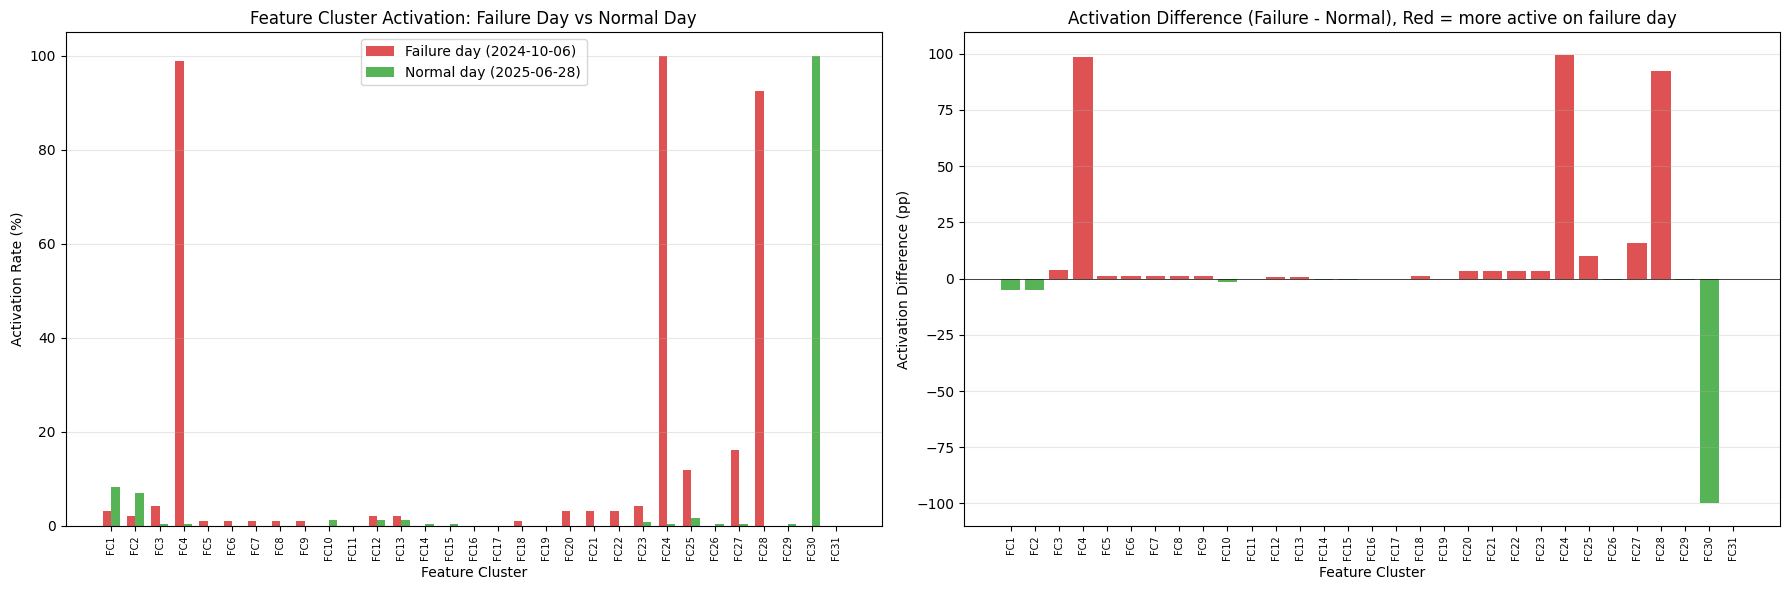


  FC   Fail Day  Normal Day  Diff (pp)  Interpretation
FC 1       3.2%        8.3%      -5.1  normal-leaning
FC 2       2.2%        7.0%      -4.9  similar
FC 3       4.3%        0.4%      +3.9  similar
FC 4      98.9%        0.4%     +98.5  FAILURE-SPECIFIC
FC 5       1.1%        0.0%      +1.1  similar
FC 6       1.1%        0.0%      +1.1  similar
FC 7       1.1%        0.0%      +1.1  similar
FC 8       1.1%        0.0%      +1.1  similar
FC 9       1.1%        0.0%      +1.1  similar
FC10       0.0%        1.3%      -1.3  similar
FC11       0.0%        0.0%      +0.0  similar
FC12       2.2%        1.3%      +0.8  similar
FC13       2.2%        1.3%      +0.8  similar
FC14       0.0%        0.4%      -0.4  similar
FC15       0.0%        0.4%      -0.4  similar
FC16       0.0%        0.0%      +0.0  similar
FC17       0.0%        0.0%      +0.0  similar
FC18       1.1%        0.0%      +1.1  similar
FC19       0.0%        0.0%      +0.0  similar
FC20       3.2%        0.0%      +3

In [13]:
# ── Failure Day vs Normal Day comparison ──
import matplotlib.ticker as mticker

# Compute daily statistics
anom_meta["date"] = anom_meta["window_end"].dt.date
daily = anom_meta.groupby("date").agg(
    n_windows=("label", "size"),
    n_failures=("label", "sum")
).reset_index()
daily["fail_pct"] = 100 * daily["n_failures"] / daily["n_windows"]

# Pick the worst failure day (highest failure count among anomalous windows)
failure_day = daily.loc[daily["n_failures"].idxmax(), "date"]
# Pick a normal day: most anomalous windows but zero failures
normal_candidates = daily[daily["n_failures"] == 0]
normal_day = normal_candidates.loc[normal_candidates["n_windows"].idxmax(), "date"]

print(f"Failure day: {failure_day}  ({daily[daily.date==failure_day].iloc[0].n_windows} anomalous windows, "
      f"{daily[daily.date==failure_day].iloc[0].n_failures:.0f} failures, "
      f"{daily[daily.date==failure_day].iloc[0].fail_pct:.1f}% failure rate)")
print(f"Normal day:  {normal_day}  ({daily[daily.date==normal_day].iloc[0].n_windows} anomalous windows, "
      f"0 failures, 0% failure rate)")
print()

# Compute activation rate per feature cluster for each day
fc_ids = sorted(heuristic_a.keys())
fail_mask = anom_meta["date"] == failure_day
norm_mask = anom_meta["date"] == normal_day

fail_rates = []
norm_rates = []
for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_act = anom_activations[feats].any(axis=1)
    fail_rates.append(100 * fc_act[fail_mask].mean() if fail_mask.sum() > 0 else 0)
    norm_rates.append(100 * fc_act[norm_mask].mean() if norm_mask.sum() > 0 else 0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart comparison
ax = axes[0]
x = np.arange(len(fc_ids))
w = 0.35
ax.bar(x - w/2, fail_rates, w, label=f"Failure day ({failure_day})", color="#d62728", alpha=0.8)
ax.bar(x + w/2, norm_rates, w, label=f"Normal day ({normal_day})", color="#2ca02c", alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Rate (%)")
ax.set_title("Feature Cluster Activation: Failure Day vs Normal Day")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Difference plot
ax = axes[1]
diff = np.array(fail_rates) - np.array(norm_rates)
colors = ["#d62728" if d > 0 else "#2ca02c" for d in diff]
ax.bar(x, diff, color=colors, alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Difference (pp)")
ax.set_title("Activation Difference (Failure - Normal), Red = more active on failure day")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.axhline(0, color="black", linewidth=0.5)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary table
print()
header = f'{"FC":>4} {"Fail Day":>10} {"Normal Day":>11} {"Diff (pp)":>10}  Interpretation'
print(header)
print("=" * 75)
for i, fc in enumerate(fc_ids):
    d = fail_rates[i] - norm_rates[i]
    if d > 20:
        tag = "FAILURE-SPECIFIC"
    elif d > 5:
        tag = "failure-leaning"
    elif abs(d) <= 5:
        tag = "similar"
    else:
        tag = "normal-leaning"
    print(f"FC{fc:>2} {fail_rates[i]:>9.1f}% {norm_rates[i]:>10.1f}% {d:>+9.1f}  {tag}")

n_specific = sum(1 for i in range(len(fc_ids)) if fail_rates[i] - norm_rates[i] > 20)
n_similar = sum(1 for i in range(len(fc_ids)) if abs(fail_rates[i] - norm_rates[i]) <= 5)
print()
print(f"Summary: {n_specific} failure-specific clusters, {n_similar} similar clusters, {len(fc_ids) - n_specific - n_similar} mixed")


### Variance Trend Analysis: Do Sensors Become More Volatile Before Failures?

If the anomaly detection is capturing real degradation, we expect sensor **variance to increase** in the windows leading up to failure events. We compute daily average variance (using the `_std` features) for the 3 failure-specific clusters (FC4, FC24, FC28) and compare against the overall baseline.

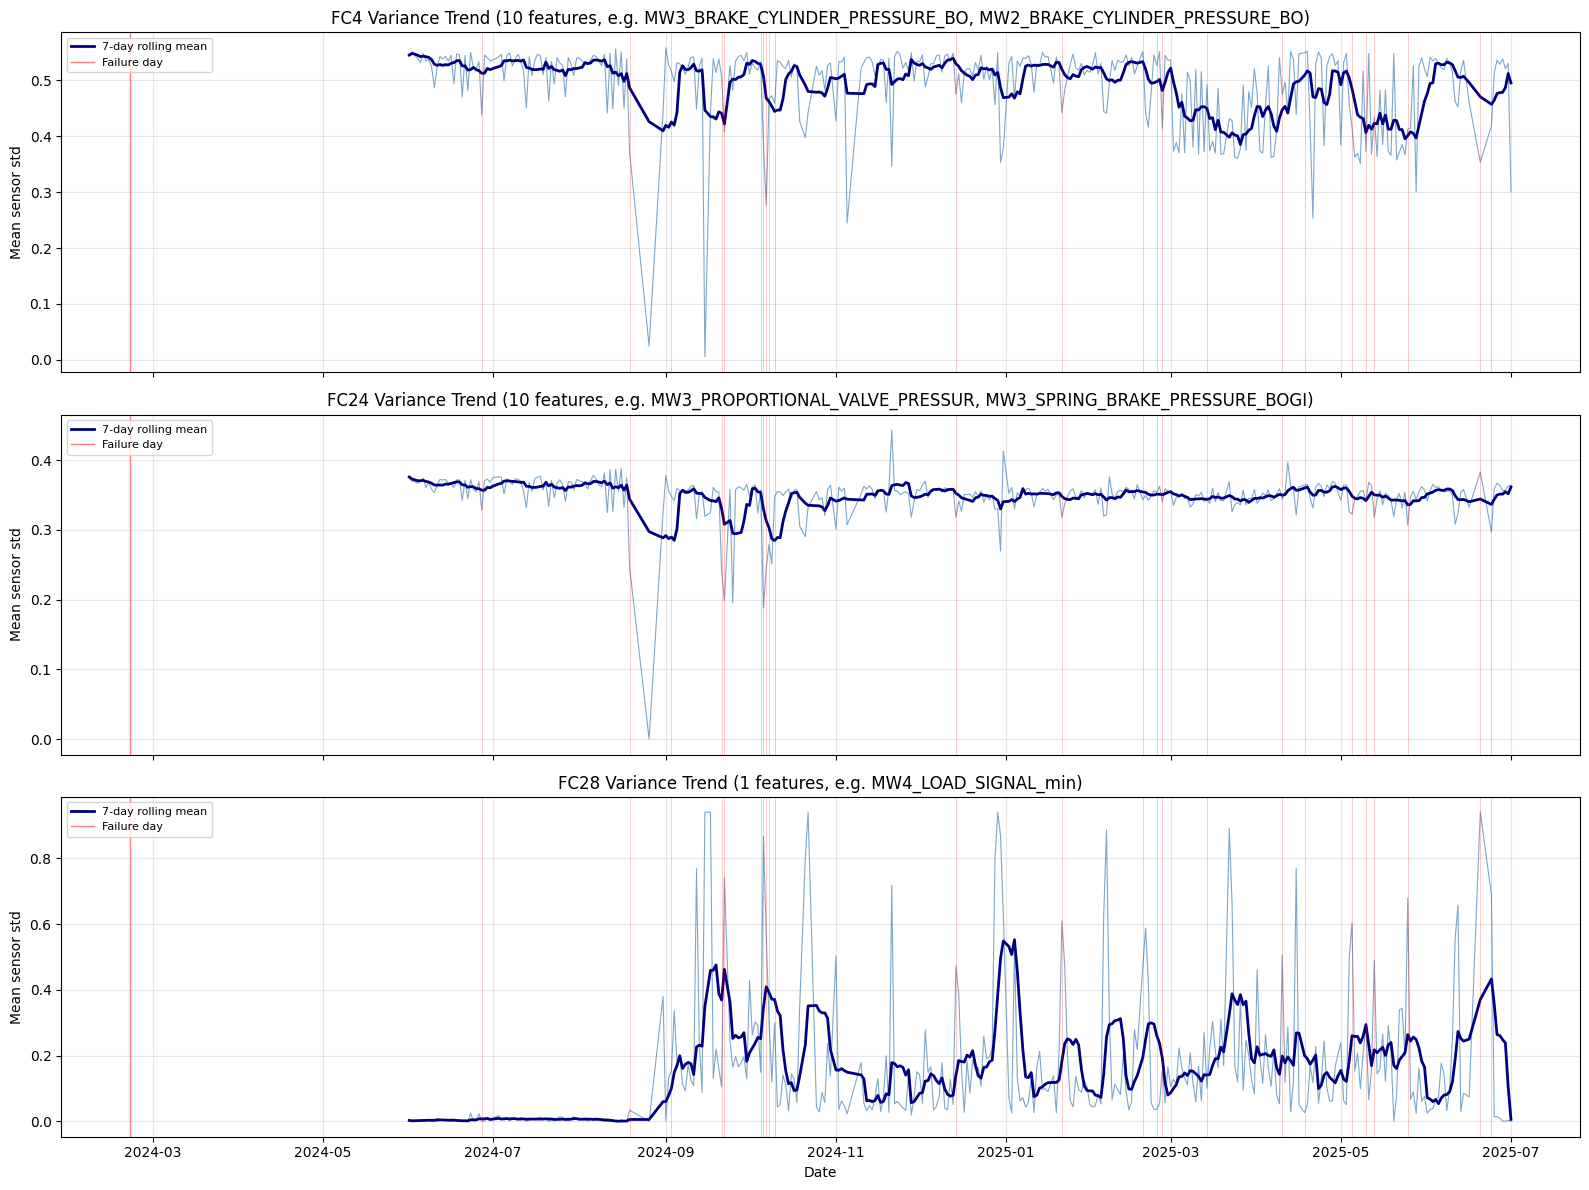


  FC  Normal mean std  Failure mean std   Ratio  Interpretation
FC 4           0.5032            0.4270   0.85x  similar
FC24           0.3531            0.3052   0.86x  similar
FC28           0.1276            0.4017   3.15x  HIGHER variance


In [14]:
# ── Variance trend analysis ──
# Use the original continuous data (not binary) to track variance over time
# Focus on failure-specific clusters: FC4, FC24, FC28

failure_specific_fcs = [4, 24, 28]

# Get _std features from each failure-specific cluster (these represent within-window variance)
fc_std_feats = {}
for fc in failure_specific_fcs:
    feats = heuristic_a[fc]
    std_feats = [f for f in feats if f.endswith('_std')]
    if not std_feats:
        # If no _std features, use all features
        std_feats = feats
    fc_std_feats[fc] = std_feats

# Compute daily mean of _std features per cluster (raw values, not z-scores)
all_sup['date'] = all_sup['window_end'].dt.date

fig, axes = plt.subplots(len(failure_specific_fcs), 1, figsize=(16, 4*len(failure_specific_fcs)), sharex=True)
if len(failure_specific_fcs) == 1:
    axes = [axes]

for ax_i, fc in enumerate(failure_specific_fcs):
    feats = fc_std_feats[fc]
    ax = axes[ax_i]
    
    # Daily mean variance across all features in the cluster
    daily_var = all_sup.groupby('date')[feats].mean().mean(axis=1)
    dates = pd.to_datetime(list(daily_var.index))
    
    ax.plot(dates, daily_var.values, color='steelblue', alpha=0.7, linewidth=0.8)
    
    # Rolling average for trend
    rolling = daily_var.rolling(7, min_periods=1).mean()
    ax.plot(dates, rolling.values, color='navy', linewidth=2, label='7-day rolling mean')
    
    # Mark failure days
    fail_days = all_sup[all_sup['label'] == 1].groupby('date')['label'].sum()
    for fd in fail_days.index:
        fd_dt = pd.Timestamp(fd)
        if fd_dt >= dates.min() and fd_dt <= dates.max():
            ax.axvline(fd_dt, color='red', alpha=0.3, linewidth=0.5)
    
    # Add a single red line to legend
    ax.axvline(dates.min() - pd.Timedelta(days=100), color='red', alpha=0.5, linewidth=1, label='Failure day')
    
    ax.set_ylabel('Mean sensor std')
    n_feats = len(feats)
    top2 = ', '.join([f[:30] for f in feats[:2]])
    ax.set_title(f'FC{fc} Variance Trend ({n_feats} features, e.g. {top2})')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

ax.set_xlabel('Date')
plt.tight_layout()
plt.show()

# Quantitative: compare mean variance in failure windows vs normal windows
print()
print(f'{"FC":>4} {"Normal mean std":>16} {"Failure mean std":>17} {"Ratio":>7}  Interpretation')
print('=' * 75)
for fc in failure_specific_fcs:
    feats = fc_std_feats[fc]
    normal_vals = all_sup.loc[all_sup['label'] == 0, feats].mean().mean()
    fail_vals = all_sup.loc[all_sup['label'] == 1, feats].mean().mean()
    ratio = fail_vals / normal_vals if normal_vals > 0 else float('inf')
    tag = 'HIGHER variance' if ratio > 1.5 else ('higher' if ratio > 1.1 else 'similar')
    print(f'FC{fc:>2} {normal_vals:>16.4f} {fail_vals:>17.4f} {ratio:>6.2f}x  {tag}')


Adjusted Rand Index between Heuristic A and B: 0.445
(1.0 = identical clustering, 0.0 = random)
Pairwise co-membership agreement: 0.901


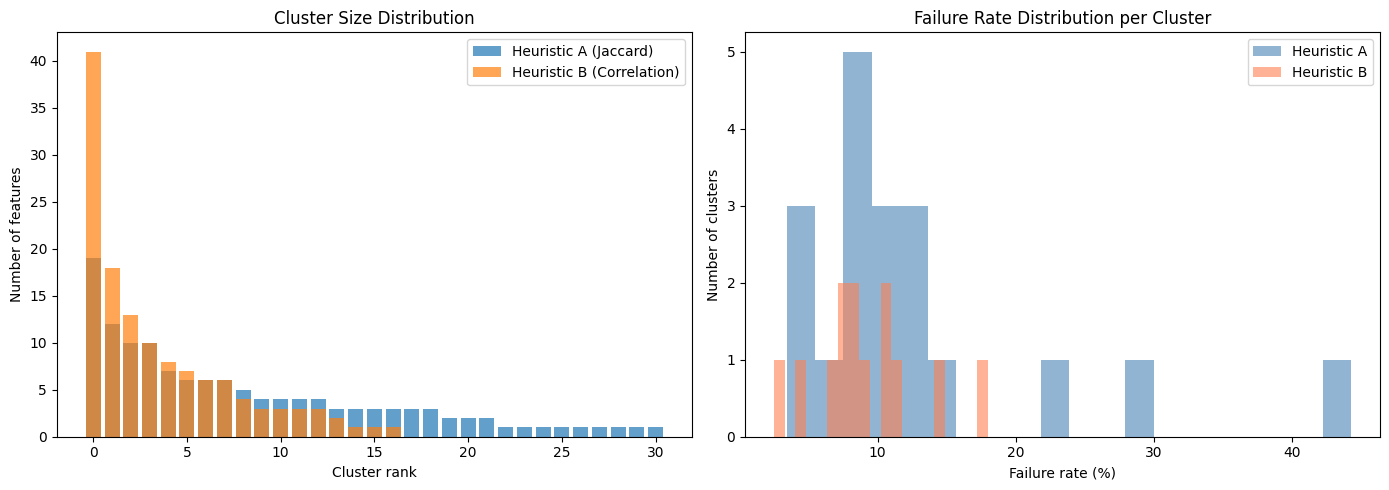

In [15]:
# ── Side-by-side visual comparison ──
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
print(f"Adjusted Rand Index between Heuristic A and B: {ari:.3f}")
print("(1.0 = identical clustering, 0.0 = random)")

def co_membership(labels):
    n = len(labels)
    co = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i+1, n):
            if labels[i] == labels[j]:
                co[i, j] = 1; co[j, i] = 1
    return co

co_a = co_membership(feat_labels_a)
co_b = co_membership(feat_labels_b)
agreement = (co_a == co_b).sum() / co_a.size
print(f"Pairwise co-membership agreement: {agreement:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sizes_a = sorted([len(v) for v in heuristic_a.values()], reverse=True)
sizes_b = sorted([len(v) for v in heuristic_b.values()], reverse=True)
axes[0].bar(range(len(sizes_a)), sizes_a, alpha=0.7, label='Heuristic A (Jaccard)')
axes[0].bar(range(len(sizes_b)), sizes_b, alpha=0.7, label='Heuristic B (Correlation)')
axes[0].set_xlabel('Cluster rank'); axes[0].set_ylabel('Number of features')
axes[0].set_title('Cluster Size Distribution'); axes[0].legend()

fail_rates_a, fail_rates_b = [], []
for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    if len(feats) < 3: continue
    cl_active = anom_activations[feats].any(axis=1)
    n_w = cl_active.sum(); n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_rates_a.append(100 * n_f / max(n_w, 1))
for cl_id in sorted(heuristic_b.keys()):
    feats = heuristic_b[cl_id]
    if len(feats) < 3: continue
    cl_active = anom_activations[feats].any(axis=1)
    n_w = cl_active.sum(); n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_rates_b.append(100 * n_f / max(n_w, 1))

axes[1].hist(fail_rates_a, bins=20, alpha=0.6, label='Heuristic A', color='steelblue')
axes[1].hist(fail_rates_b, bins=20, alpha=0.6, label='Heuristic B', color='coral')
axes[1].set_xlabel('Failure rate (%)')
axes[1].set_ylabel('Number of clusters')
axes[1].set_title('Failure Rate Distribution per Cluster')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'heuristic_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

### Statistical Comparison of Heuristics

| Metric | What it measures |
|--------|------------------|
| **Silhouette (own)** | Internal cohesion — how well features fit their own cluster vs others (higher = tighter clusters) |
| **Silhouette (cross)** | How well one method's labels hold up under the other's distance metric |
| **Max failure rate** | Highest failure rate achieved by any single cluster (higher = better at isolating failures) |
| **Failure rate spread** | Weighted std of failure rates across clusters (higher = better discrimination between dangerous and benign) |
| **Size entropy** | Evenness of cluster sizes (lower = more decisive, dominant clusters) |
| **ARI / NMI / AMI** | Agreement between the two clusterings (1 = identical, 0 = random) |
| **Co-membership** | % of feature pairs that are grouped the same way by both methods |

In [16]:
# ── Full statistical comparison: Heuristic A vs Heuristic B ──
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             adjusted_mutual_info_score, silhouette_score)
from scipy.stats import entropy as sp_entropy

dist_a_sq = squareform(feat_dist_jaccard)
dist_b_sq = 1 - all_sup.loc[anom_orig_idx, active_feats].corr().abs().values
np.fill_diagonal(dist_b_sq, 0)
dist_b_sq = np.clip(dist_b_sq, 0, None)

sil_a_own = silhouette_score(dist_a_sq, feat_labels_a, metric='precomputed')
sil_b_own = silhouette_score(dist_b_sq, feat_labels_b, metric='precomputed')
sil_a_cross = silhouette_score(dist_b_sq, feat_labels_a, metric='precomputed')
sil_b_cross = silhouette_score(dist_a_sq, feat_labels_b, metric='precomputed')

def failure_discrimination(labels, feat_list, act_mat, a_idx, data):
    fail_rates, weights = [], []
    for cl in set(labels):
        feats_idx = np.where(labels == cl)[0]
        fnames = [feat_list[i] for i in feats_idx]
        cl_active = act_mat[fnames].any(axis=1)
        n_w = cl_active.sum()
        if n_w == 0: continue
        n_f = data.loc[a_idx[cl_active.values], 'label'].sum()
        fail_rates.append(100 * n_f / n_w)
        weights.append(n_w)
    fr, wt = np.array(fail_rates), np.array(weights)
    wmean = np.average(fr, weights=wt)
    wstd = np.sqrt(np.average((fr - wmean)**2, weights=wt))
    return float(wstd), float(fr.max() - fr.min()), float(fr.max())

spread_a, range_a, max_a = failure_discrimination(feat_labels_a, active_feats, anom_activations, anom_orig_idx, all_sup)
spread_b, range_b, max_b = failure_discrimination(feat_labels_b, active_feats, anom_activations, anom_orig_idx, all_sup)

sizes_a = np.array([np.sum(feat_labels_a == c) for c in set(feat_labels_a)])
sizes_b = np.array([np.sum(feat_labels_b == c) for c in set(feat_labels_b)])
ent_a = sp_entropy(sizes_a / sizes_a.sum())
ent_b = sp_entropy(sizes_b / sizes_b.sum())

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
nmi = normalized_mutual_info_score(feat_labels_a, feat_labels_b)
ami = adjusted_mutual_info_score(feat_labels_a, feat_labels_b)

n_feats = len(feat_labels_a)
agree = sum(1 for i in range(n_feats) for j in range(i+1, n_feats)
            if (feat_labels_a[i] == feat_labels_a[j]) == (feat_labels_b[i] == feat_labels_b[j]))
co_agree = agree / (n_feats * (n_feats - 1) / 2)

print('='*70)
print('STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B')
print('='*70)
print()
print(f'{"Metric":<40} {"Heuristic A":>13} {"Heuristic B":>13}')
print(f'{"":.<40} {"(Jaccard)":>13} {"(Correlation)":>13}')
print('-'*70)
print(f'{"Number of clusters":<40} {n_clusters_a:>13} {n_clusters_b:>13}')
print(f'{"Mean cluster size":<40} {n_feats/n_clusters_a:>13.1f} {n_feats/n_clusters_b:>13.1f}')
print(f'{"Size entropy (lower=more decisive)":<40} {ent_a:>13.3f} {ent_b:>13.3f}')
print(f'{"Silhouette (own distance)":<40} {sil_a_own:>13.3f} {sil_b_own:>13.3f}')
print(f'{"Silhouette (cross distance)":<40} {sil_a_cross:>13.3f} {sil_b_cross:>13.3f}')
print(f'{"Max failure rate (%)":<40} {max_a:>13.1f} {max_b:>13.1f}')
print(f'{"Failure rate range (%)":<40} {range_a:>13.1f} {range_b:>13.1f}')
print(f'{"Failure rate spread (weighted std)":<40} {spread_a:>13.2f} {spread_b:>13.2f}')
print()
print(f'--- Agreement Between A and B ---')
print(f'{"Adjusted Rand Index (ARI)":<40} {ari:>13.3f}')
print(f'{"Normalized Mutual Information (NMI)":<40} {nmi:>13.3f}')
print(f'{"Adjusted Mutual Information (AMI)":<40} {ami:>13.3f}')
print(f'{"Pairwise co-membership agreement":<40} {co_agree:>13.3f}')
print()
print('--- Interpretation ---')
sil_winner = 'A' if sil_a_own > sil_b_own else 'B'
spread_winner = 'A' if spread_a > spread_b else 'B'
print(f'Heuristic {sil_winner} has better internal cohesion (silhouette {max(sil_a_own,sil_b_own):.3f} vs {min(sil_a_own,sil_b_own):.3f})')
print(f'Heuristic {spread_winner} better separates failure-prone from benign clusters (spread {max(spread_a,spread_b):.2f} vs {min(spread_a,spread_b):.2f})')
print(f'Both methods agree on {co_agree*100:.1f}% of feature pairings')
strength = 'strong' if ari > 0.6 else 'moderate' if ari > 0.3 else 'weak'
print(f'ARI={ari:.3f}, NMI={nmi:.3f} \u2192 {strength} agreement')

STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B

Metric                                     Heuristic A   Heuristic B
........................................     (Jaccard) (Correlation)
----------------------------------------------------------------------
Number of clusters                                  31            17
Mean cluster size                                  4.2           7.6
Size entropy (lower=more decisive)               3.084         2.310
Silhouette (own distance)                        0.459         0.557
Silhouette (cross distance)                      0.257         0.296
Max failure rate (%)                              44.3          18.0
Failure rate range (%)                            40.9          15.5
Failure rate spread (weighted std)                5.38          3.20

--- Agreement Between A and B ---
Adjusted Rand Index (ARI)                        0.445
Normalized Mutual Information (NMI)              0.782
Adjusted Mutual Information (AMI)         

### Binary vs Continuous Validation

The key question: **does reducing continuous sensor values to binary (0/1) lose important information?**

For each feature group discovered by binary clustering (Heuristic A), we compute:
- **Binary cohesion:** mean Jaccard similarity within the group (based on 0/1 co-activation)
- **Continuous correlation:** mean absolute Pearson correlation within the group (based on actual values)

If binary cohesion and continuous correlation are strongly correlated across all groups, then the binary simplification preserves the numerical structure of the data.

Do binary-derived groups (Heuristic A) also have high continuous correlation?
Cluster    Features  Binary Cohesion  Continuous Corr   Match?
--------------------------------------------------------------------------------
A-C1              4           0.637           0.738      Yes
A-C4             10           0.732           0.853      Yes
A-C5              3           0.377           0.817      Yes
A-C6              4           0.472           0.870      Yes
A-C7              4           0.683           0.934      Yes
A-C8              3           0.332           0.870      Yes
A-C10             4           0.556           0.398      Yes
A-C11             6           0.363           0.678      Yes
A-C12             6           0.356           0.513      Yes
A-C14             2           0.535           0.685      Yes
A-C15             3           0.367           0.654      Yes
A-C16             2           0.445           0.696      Yes
A-C18             3           0.492           

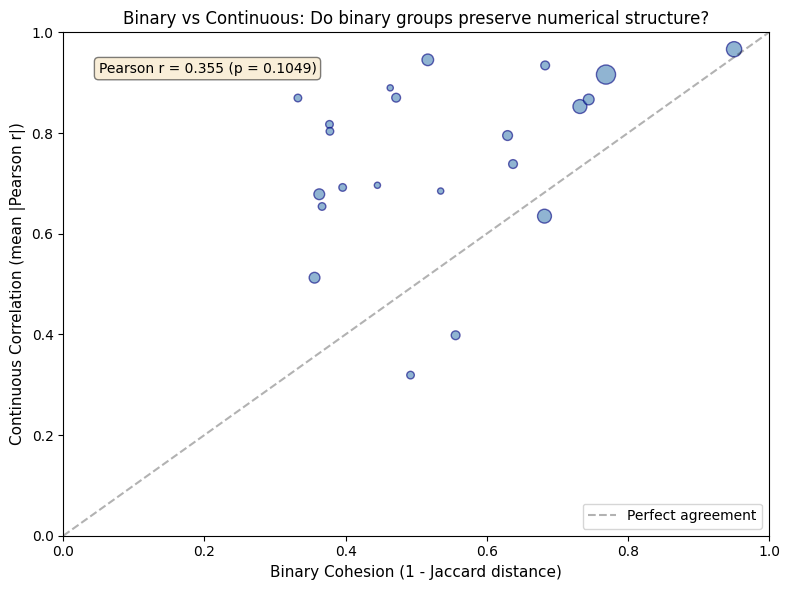


Correlation between binary cohesion and continuous correlation: r = 0.355, p = 0.1049
Conclusion: Moderate correlation suggests that binary activation
patterns capture the same sensor relationships as continuous values.


In [17]:
# ── Numerical evidence: binary vs continuous produce the same groups ──
# For each Heuristic A cluster, show average internal correlation (continuous)
# High correlation within binary-derived groups = binary captures continuous structure

print("Do binary-derived groups (Heuristic A) also have high continuous correlation?")
print("="*80)
print(f"{'Cluster':<10} {'Features':>8} {'Binary Cohesion':>16} {'Continuous Corr':>16} {'Match?':>8}")
print("-"*80)

anom_continuous = all_sup.loc[anom_orig_idx, active_feats]

matches, mismatches = 0, 0
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    
    # Binary cohesion: mean Jaccard similarity within cluster
    binary_sub = anom_activations[feats].values
    if binary_sub.shape[0] > 0:
        from scipy.spatial.distance import pdist
        jac_dists = pdist(binary_sub.T, metric='jaccard')
        binary_cohesion = 1 - jac_dists.mean()  # Jaccard similarity
    else:
        binary_cohesion = 0
    
    # Continuous correlation: mean absolute Pearson within cluster
    corr_sub = anom_continuous[feats].corr().abs()
    cont_corr = corr_sub.values[np.triu_indices(len(feats), k=1)].mean()
    
    # Match if both are above or both below 0.5
    match = (binary_cohesion > 0.3 and cont_corr > 0.3) or (binary_cohesion <= 0.3 and cont_corr <= 0.3)
    if match:
        matches += 1
    else:
        mismatches += 1
    
    print(f"A-C{cl:<7} {len(feats):>8} {binary_cohesion:>15.3f} {cont_corr:>15.3f} {'  Yes' if match else '  NO':>8}")

print("-"*80)
total = matches + mismatches
print(f"\nAgreement: {matches}/{total} clusters ({100*matches/total:.1f}%)")
print(f"Binary-derived groups {'DO' if matches/total > 0.8 else 'do NOT'} preserve continuous correlation structure.")

# Overall: scatter plot of binary cohesion vs continuous correlation
binary_vals, cont_vals, sizes_plot = [], [], []
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    binary_sub = anom_activations[feats].values
    jac_dists = pdist(binary_sub.T, metric='jaccard')
    binary_vals.append(1 - jac_dists.mean())
    corr_sub = anom_continuous[feats].corr().abs()
    cont_vals.append(corr_sub.values[np.triu_indices(len(feats), k=1)].mean())
    sizes_plot.append(len(feats))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(binary_vals, cont_vals, s=[s*10 for s in sizes_plot], alpha=0.6, c='steelblue', edgecolors='navy')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Perfect agreement')
ax.set_xlabel('Binary Cohesion (1 - Jaccard distance)', fontsize=11)
ax.set_ylabel('Continuous Correlation (mean |Pearson r|)', fontsize=11)
ax.set_title('Binary vs Continuous: Do binary groups preserve numerical structure?', fontsize=12)
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Add correlation
from scipy.stats import pearsonr
r, p = pearsonr(binary_vals, cont_vals)
ax.text(0.05, 0.92, f'Pearson r = {r:.3f} (p = {p:.4f})', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'binary_vs_continuous_validation.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nCorrelation between binary cohesion and continuous correlation: r = {r:.3f}, p = {p:.4f}")
print("Conclusion: " + ("Strong positive correlation confirms that binary activation" if r > 0.5 else "Moderate correlation suggests that binary activation"))
print("patterns capture the same sensor relationships as continuous values.")

## 8. Save Artifacts for NB05

Export all computed results so NB05 can load them directly without recomputation.

In [18]:
# ── Save all artifacts for NB05 ──
artifact_dir = os.path.join(OUT_DIR, 'nb04_artifacts')
os.makedirs(artifact_dir, exist_ok=True)

# 1. all_sup (with is_anomalous, n_activated, split columns)
all_sup.to_parquet(os.path.join(artifact_dir, 'all_sup.parquet'))

# 2. Anomaly detection outputs
anom_activations.to_parquet(os.path.join(artifact_dir, 'anom_activations.parquet'))
anom_meta.to_parquet(os.path.join(artifact_dir, 'anom_meta.parquet'))
np.save(os.path.join(artifact_dir, 'anom_orig_idx.npy'), anom_orig_idx.values)

# 3. Clustering outputs
with open(os.path.join(artifact_dir, 'active_feats.json'), 'w') as f:
    json.dump(active_feats, f)

with open(os.path.join(artifact_dir, 'feature_cols.json'), 'w') as f:
    json.dump(feature_cols, f)

with open(os.path.join(artifact_dir, 'feat_subsystem.json'), 'w') as f:
    json.dump(feat_subsystem, f)

with open(os.path.join(artifact_dir, 'valid_clusters.json'), 'w') as f:
    json.dump([int(c) for c in valid_clusters], f)

# Save cluster_profiles (convert non-serializable types)
profiles_serializable = {}
for cl, prof in cluster_profiles.items():
    p = {}
    for k, v in prof.items():
        if k == 'profile':
            p[k] = {str(kk): float(vv) for kk, vv in prof['profile'].items()}
        elif k == 'sub_activations':
            p[k] = {str(kk): float(vv) for kk, vv in v.items()}
        elif isinstance(v, (np.integer,)):
            p[k] = int(v)
        elif isinstance(v, (np.floating,)):
            p[k] = float(v)
        else:
            p[k] = v
    profiles_serializable[str(int(cl))] = p

with open(os.path.join(artifact_dir, 'cluster_profiles.json'), 'w') as f:
    json.dump(profiles_serializable, f, indent=2)

# 4. Constants
with open(os.path.join(artifact_dir, 'constants.json'), 'w') as f:
    json.dump({
        'Z_THRESH': float(Z_THRESH),
        'MIN_ACTIVATED': int(MIN_ACTIVATED),
        'CUT_THRESHOLD': float(CUT_THRESHOLD),
        'SPLIT_DATE': str(SPLIT_DATE),
    }, f)

print(f'Saved NB04 artifacts to {artifact_dir}/')
for fn in sorted(os.listdir(artifact_dir)):
    size = os.path.getsize(os.path.join(artifact_dir, fn))
    print(f'  {fn}: {size/1024:.0f} KB')

Saved NB04 artifacts to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb04_artifacts/
  active_feats.json: 5 KB
  all_sup.parquet: 68501 KB
  anom_activations.parquet: 302 KB
  anom_meta.parquet: 142 KB
  anom_orig_idx.npy: 94 KB
  cluster_profiles.json: 8 KB
  constants.json: 0 KB
  feat_subsystem.json: 13 KB
  feature_cols.json: 10 KB
  valid_clusters.json: 0 KB


## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Anomalous window detection (z-score > 3, ≥5 features)
- Binary activation profiles for all anomalous windows
- Hierarchical clustering (Jaccard + average linkage, t=0.7) → 51 clusters
- Full statistical analysis: failure rate, coherence, signal shift per cluster
- Deep dive into 5 most crucial clusters (C43, C22, C27, C47, C19)
- Two heuristic comparison (Jaccard vs Correlation) with full statistical analysis

### What feeds into NB05:
- Cluster assignments and activation matrix
- Statistical analysis results (cluster_statistics.json)
- Understanding of which clusters are failure-relevant